# 🔬 Lab Task 03 — Edge Detection Techniques and Their Impact on Classification Performance
### HAM10000 Dataset | continues the Lab 02 codebase (EfficientNet-B3 · ResNet-50 + SVM · RF · KNN)
**Student:** Abdul Rehman | FA23-BAI-036

---
This notebook continues **Lab 02** (same Kaggle source, same metadata decoding, same class map, same `apply_filter()`, same model heads and optimiser settings, same 80/20 split with `SEED = 42`).

**Download-once design** — everything is fetched/computed *before* any training starts:
1. **Section 3** downloads the dataset **and** the ImageNet weights of both CNNs once (weights are kept in memory; every experiment only copies them).
2. **Section 10** applies the Lab 02 filter and the Lab 03 edge detector to every image **once** and caches the three datasets in RAM and on disk (`lab03_cache/`). Training epochs never re-read or re-filter images.



## 📦 Section 1 — Install Dependencies

In [1]:
!pip install -q kagglehub torch torchvision scikit-learn matplotlib seaborn pandas tqdm opencv-python-headless
print("✅ All packages installed")

✅ All packages installed


## ⚙️ Section 2 — Imports & Global Config

In [2]:
import os, re, time, random, warnings, shutil, json, copy, datetime
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import (efficientnet_b3, EfficientNet_B3_Weights,
                                resnet50, ResNet50_Weights)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)

# ── Reproducibility (same as Lab 02) ──────────────────────────────────────────
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
set_seed()

# ── Hyper-parameters (Lab 02 values; identical for Raw / Filtered / Edge) ─────
BATCH_SIZE   = 32
EPOCHS       = 10
LR           = 1e-4
WEIGHT_DECAY = 1e-4
NUM_CLASSES  = 7

# ── Image sizes ───────────────────────────────────────────────────────────────
ANALYSIS_SIZE  = 256   # edge-detection analysis (Tasks 1-3)
CNN_SIZE       = 160   # CNN input (cached once in RAM → fast epochs on a T4)
CLASSICAL_SIZE = 64    # flattened input of SVM / RF / KNN
PCA_DIM        = 100

# ── Best filter from Lab 02 → Set B ───────────────────────────────────────────
# Lab 02 (EfficientNet-B3, val macro-F1): No filter 0.563 | Sharpening 0.564 | Median 0.538
#                                          Gaussian 0.537 | Average 0.531 | Sobel ≪ 0.30
BEST_FILTER = "sharpening"

# ── Noise for Task 2 ──────────────────────────────────────────────────────────
GAUSS_SIGMA = 20
SP_AMOUNT   = 0.05

RESULTS_DIR = "lab03_results"
PLOT_DIR    = os.path.join(RESULTS_DIR, "plots")
CACHE_DIR   = "lab03_cache"
for d in (RESULTS_DIR, PLOT_DIR, CACHE_DIR): os.makedirs(d, exist_ok=True)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print(f"Device : {DEVICE}")
print(f"CUDA   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
CUDA   : True
GPU    : Tesla T4


## 📥 Section 3 — One-Time Downloads (dataset + pretrained weights)
Everything that needs the internet is done **here, once**. After this cell no download happens again — the CNN builders in Section 12 copy the in-memory state dicts.

In [3]:
import kagglehub

# ── 1. Dataset (Lab 02 source) ────────────────────────────────────────────────
t0 = time.time()
BASE_PATH = kagglehub.dataset_download("surajghuwalewala/ham1000-segmentation-and-classification")
print(f"✅ Dataset ready at {BASE_PATH}  ({time.time()-t0:.0f}s)")

# ── 2. ImageNet weights for both CNNs — downloaded once, kept in memory ───────
WEIGHT_ENUMS = {"efficientnet_b3": EfficientNet_B3_Weights.IMAGENET1K_V1,
                "resnet50":        ResNet50_Weights.IMAGENET1K_V2}
PRETRAINED_WEIGHTS = {}
for name, enum in WEIGHT_ENUMS.items():
    t0 = time.time()
    try:
        PRETRAINED_WEIGHTS[name] = enum.get_state_dict(progress=True)
        n = sum(v.numel() for v in PRETRAINED_WEIGHTS[name].values())
        print(f"✅ {name:16s} weights loaded once ({n/1e6:.1f}M params, {time.time()-t0:.0f}s)")
    except Exception as e:
        PRETRAINED_WEIGHTS[name] = None
        print(f"⚠️ {name}: could not download ImageNet weights ({type(e).__name__}) → random init will be used")
print("\n🔒 All downloads finished — training will not download anything.")

100%|██████████| 2.59G/2.59G [00:30<00:00, 90.2MB/s]

Extracting files...


✅ Dataset ready at /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2  (49s)
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 129MB/s]


✅ efficientnet_b3  weights loaded once (12.3M params, 1s)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 196MB/s]


✅ resnet50         weights loaded once (25.6M params, 1s)

🔒 All downloads finished — training will not download anything.


## 📁 Section 4 — Paths, Metadata & Split (Lab 02 code)

In [4]:
IMG_DIR, CSV_PATH = None, None
for root, dirs, files in os.walk(BASE_PATH):
    jpgs = [f for f in files if f.endswith('.jpg')]
    csvs = [f for f in files if f.endswith('.csv')]
    if jpgs and IMG_DIR is None:
        IMG_DIR = root; print(f"✅ Images found at : {IMG_DIR}  ({len(jpgs)} jpg files)")
    if csvs and CSV_PATH is None:
        CSV_PATH = os.path.join(root, csvs[0]); print(f"✅ CSV found at    : {CSV_PATH}")
assert IMG_DIR is not None and CSV_PATH is not None

CLASS_NAMES  = {'akiec':0,'bcc':1,'bkl':2,'df':3,'mel':4,'nv':5,'vasc':6}
IDX_TO_CLASS = {v:k for k,v in CLASS_NAMES.items()}
CLASS_FULL   = {'akiec':'Actinic Keratoses','bcc':'Basal Cell Carcinoma','bkl':'Benign Keratosis',
                'df':'Dermatofibroma','mel':'Melanoma','nv':'Melanocytic Nevi','vasc':'Vascular Lesions'}
CLASSES = list(CLASS_NAMES.keys())
cls2idx = CLASS_NAMES

df_raw = pd.read_csv(CSV_PATH)
ONEHOT_TO_KEY = {'MEL':'mel','NV':'nv','BCC':'bcc','AKIEC':'akiec','BKL':'bkl','DF':'df','VASC':'vasc'}
onehot_cols = [c for c in df_raw.columns if c.upper() in ONEHOT_TO_KEY]
if onehot_cols:
    df_raw['dx'] = df_raw[onehot_cols].idxmax(axis=1).str.upper().map(ONEHOT_TO_KEY)
elif 'dx' not in df_raw.columns and 'label' in df_raw.columns:
    df_raw['dx'] = df_raw['label']
df_raw['label_idx'] = df_raw['dx'].map(CLASS_NAMES)
ID_COL = 'image' if 'image' in df_raw.columns else ('image_id' if 'image_id' in df_raw.columns else df_raw.columns[0])

def find_img(image_id):
    for ext in ['.jpg', '.png', '.JPG', '.PNG']:
        p = os.path.join(IMG_DIR, str(image_id) + ext)
        if os.path.exists(p): return p
    return None

df_raw['filepath'] = df_raw[ID_COL].apply(find_img)
df = df_raw.dropna(subset=['filepath', 'label_idx']).reset_index(drop=True)
df['label_idx'] = df['label_idx'].astype(int)
df['path']  = df['filepath']          # alias used by the Lab 03 helpers
df['label'] = df['label_idx']
print(f"\n✅ Total usable images : {len(df)}")
print(df['dx'].value_counts())

# ── Split: Lab 02's 80/20 split is kept; its 20 % validation set becomes the TEST set,
#    and 10 % of Lab 02's training part is held out for validation / early stopping ──
df_train_l2, df_val_l2 = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df['label_idx'])
train_df, val_df = train_test_split(df_train_l2, test_size=0.10, random_state=SEED, stratify=df_train_l2['label_idx'])
test_df  = df_val_l2
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))
print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test (= Lab 02 val set): {len(test_df)}")

✅ CSV found at    : /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/GroundTruth.csv
✅ Images found at : /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/images  (10015 jpg files)

✅ Total usable images : 10015
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Train: 7210 | Val: 802 | Test (= Lab 02 val set): 2003


## 🧰 Section 5 — Helper Functions
Noise generation, Lab 02 filters, all edge detectors and **quantitative edge-quality metrics**.

**How edge quality is measured (used for Table 1 & 2)**
* Gradient-type detectors (Sobel, Prewitt, Laplacian, LoG) are converted to binary edge maps with a threshold **fixed on the clean image** (top 10 % of responses). The *same absolute threshold* is then applied to the noisy / filtered versions, so any extra pixels that cross it are caused by the noise.
* Every noisy / filtered edge map is compared with the clean edge map of the same detector (1-pixel tolerance):
  * **False-edge %** = detected edge pixels that do not exist in the clean map → *noise sensitivity / false edges*
  * **Missed-edge %** = clean edges that disappeared → *broken edges*
  * **F1 vs clean** → overall *edge quality*
* **Continuity** = mean length (pixels) of connected edge segments; **Fragments** = number of connected segments. Long, few segments = continuous edges; many tiny segments = broken / noisy edges.

In [5]:
# ── Loading ───────────────────────────────────────────────────────────────────
def load_rgb(path, size=ANALYSIS_SIZE):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

def to_gray(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# ── Noise ─────────────────────────────────────────────────────────────────────
def add_gaussian_noise(gray, sigma=GAUSS_SIGMA, seed=0):
    rng = np.random.default_rng(seed)
    noisy = gray.astype(np.float32) + rng.normal(0, sigma, gray.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_salt_pepper(gray, amount=SP_AMOUNT, seed=0):
    rng = np.random.default_rng(seed)
    out = gray.copy()
    r = rng.random(gray.shape)
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out

# ── Smoothing filters (same kernels as Lab 02) ────────────────────────────────
def gaussian_filter(img): return cv2.GaussianBlur(img, (5, 5), 1.5)
def median_filter(img):   return cv2.medianBlur(img, 5)

def apply_filter(img_rgb, fname):
    # Identical to the Lab 02 apply_filter()
    if fname == "none":
        return img_rgb
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    if fname == "average":
        out = cv2.blur(bgr, (5, 5))
    elif fname == "gaussian":
        out = cv2.GaussianBlur(bgr, (5, 5), sigmaX=1.5)
    elif fname == "median":
        out = cv2.medianBlur(bgr, 5)
    elif fname == "sharpening":
        k = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
        out = np.clip(cv2.filter2D(bgr, -1, k), 0, 255).astype(np.uint8)
    elif fname == "sobel":
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        mag = np.sqrt(sx ** 2 + sy ** 2)
        mag = np.clip(mag / (mag.max() + 1e-8) * 255, 0, 255).astype(np.uint8)
        out = cv2.cvtColor(mag, cv2.COLOR_GRAY2BGR)
    else:
        raise ValueError(fname)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

# ── Edge detectors (input: uint8 grayscale, output: float response map) ───────
PREWITT_X = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
PREWITT_Y = PREWITT_X.T

def sobel_x(g):   return cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
def sobel_y(g):   return cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
def sobel_mag(g): return np.hypot(sobel_x(g), sobel_y(g))
def prewitt(g):
    gf = g.astype(np.float64)
    return np.hypot(cv2.filter2D(gf, cv2.CV_64F, PREWITT_X), cv2.filter2D(gf, cv2.CV_64F, PREWITT_Y))
def laplacian(g): return np.abs(cv2.Laplacian(g, cv2.CV_64F, ksize=3))
def log_edge(g, ksize=5, sigma=1.0):
    return np.abs(cv2.Laplacian(cv2.GaussianBlur(g, (ksize, ksize), sigma), cv2.CV_64F, ksize=3))

def canny(g, low=50, high=150, blur_k=5):
    # Classical Canny: (1) Gaussian smoothing  (2) Sobel gradient  (3) non-max suppression
    # (4) double threshold + hysteresis.  cv2.Canny performs steps 2-4 only, so step 1 is added here.
    if blur_k and blur_k > 1:
        g = cv2.GaussianBlur(g, (blur_k, blur_k), 0)
    return cv2.Canny(g, low, high, L2gradient=True)

GRAD_DETECTORS = {"Sobel": sobel_mag, "Prewitt": prewitt, "Laplacian": laplacian, "LoG": log_edge}
DETECTORS = ["Sobel", "Prewitt", "Laplacian", "LoG", "Canny"]

def edge_response(name, g):
    return canny(g).astype(np.float64) if name == "Canny" else GRAD_DETECTORS[name](g)

def to_display(resp, vmax=None):
    resp = np.abs(resp)
    vmax = vmax if vmax is not None else (np.percentile(resp, 99.5) + 1e-8)
    return np.clip(resp / vmax, 0, 1)

# ── Edge-quality metrics ──────────────────────────────────────────────────────
_K3 = np.ones((3, 3), np.uint8)

def binarize(resp, thr):
    return (resp >= thr).astype(np.uint8)

def edge_stats(e):
    # e: binary {0,1}. Returns density, fragment count, mean segment length
    e = e.astype(np.uint8)
    n, _ = cv2.connectedComponents(e, connectivity=8)
    frags = max(n - 1, 0)
    px = int(e.sum())
    return dict(density=px / e.size, pixels=px, fragments=frags, seg_len=px / frags if frags else 0.0)

def compare_edges(test, ref):
    # 1-pixel tolerance comparison of a test edge map against a reference edge map
    test = test.astype(np.uint8); ref = ref.astype(np.uint8)
    ref_d, test_d = cv2.dilate(ref, _K3), cv2.dilate(test, _K3)
    if test.sum() == 0 and ref.sum() == 0:
        return dict(false_pct=0.0, missed_pct=0.0, f1=1.0)
    prec = (test & ref_d).sum() / test.sum() if test.sum() else 0.0
    rec  = (ref & test_d).sum() / ref.sum() if ref.sum() else 0.0
    f1   = 2 * prec * rec / (prec + rec + 1e-8)
    return dict(false_pct=100 * (1 - prec), missed_pct=100 * (1 - rec), f1=f1)

print("✅ Helpers ready")

✅ Helpers ready


## 🖼️ Section 6 — Task 1: Comparative Edge Detection
Representative images are taken from **all 7 classes** (requirement: ≥ 3).
* **First-order:** Sobel Gₓ (vertical edges – horizontal intensity change), Sobel Gᵧ (horizontal edges), Sobel magnitude √(Gₓ²+Gᵧ²), Prewitt
* **Second-order:** Laplacian ∇²I, Laplacian of Gaussian ∇²(G*I)
* **Multi-stage:** Canny (smoothing → gradient → non-max suppression → hysteresis)

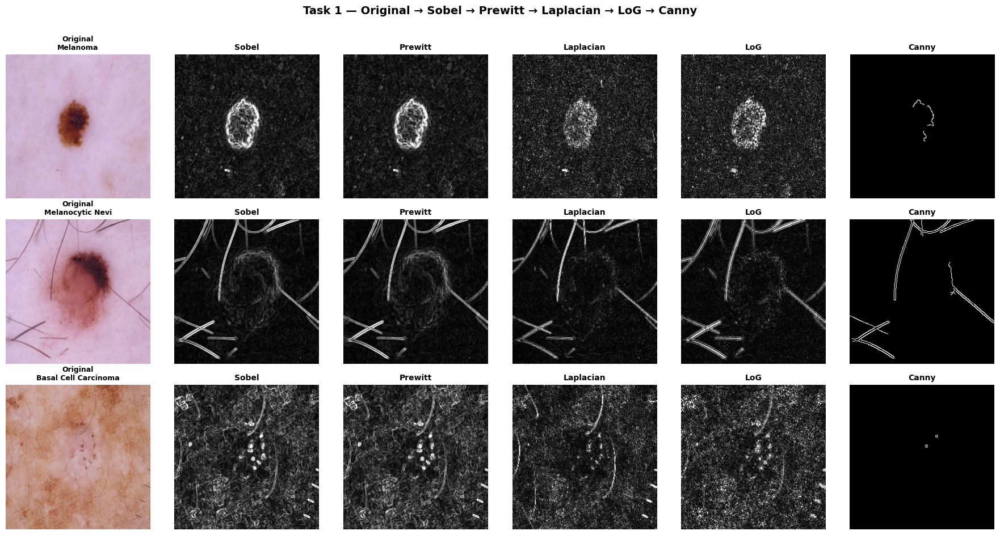

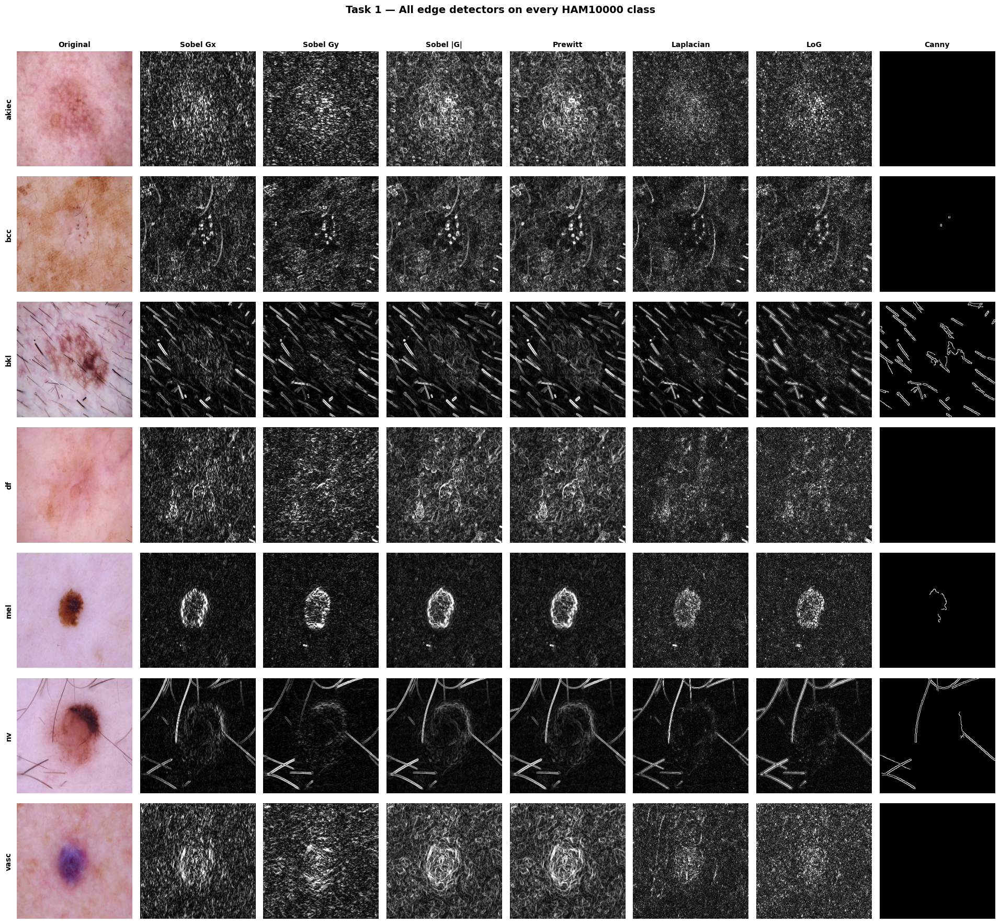

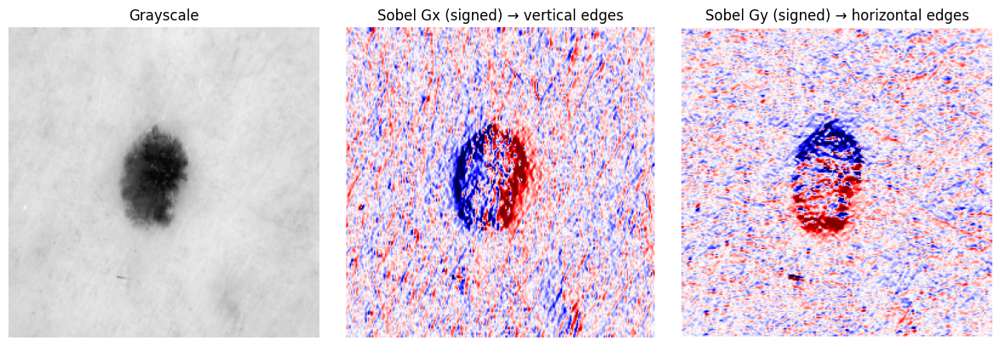

✅ Task 1 figures saved


In [6]:
rng_state = np.random.RandomState(SEED)
sample_rows = {c: train_df[train_df["dx"] == c].sample(1, random_state=SEED).iloc[0] for c in CLASSES}

# ── Required figure: Original → Sobel → Prewitt → Laplacian → LoG → Canny ─────
REQ_CLASSES = [c for c in ["mel", "nv", "bcc"] if c in CLASSES]
if len(REQ_CLASSES) < 3:
    REQ_CLASSES = CLASSES[:3]
cols = ["Original", "Sobel", "Prewitt", "Laplacian", "LoG", "Canny"]
fig, axes = plt.subplots(len(REQ_CLASSES), len(cols), figsize=(3 * len(cols), 3.1 * len(REQ_CLASSES)))
for i, c in enumerate(REQ_CLASSES):
    rgb = load_rgb(sample_rows[c]["path"]); g = to_gray(rgb)
    axes[i][0].imshow(rgb)
    for j, name in enumerate(DETECTORS, start=1):
        axes[i][j].imshow(to_display(edge_response(name, g)), cmap="gray")
    for j, t in enumerate(cols):
        axes[i][j].set_title(t, fontsize=10, fontweight="bold")
        axes[i][j].axis("off")
    axes[i][0].set_title(f"Original\n{CLASS_FULL.get(c, c)}", fontsize=9, fontweight="bold")
plt.suptitle("Task 1 — Original → Sobel → Prewitt → Laplacian → LoG → Canny", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/task1_required_chain.png", dpi=150, bbox_inches="tight"); plt.show()

# ── Extended figure: all detectors incl. Gx / Gy for all 7 classes ────────────
cols = ["Original", "Sobel Gx", "Sobel Gy", "Sobel |G|", "Prewitt", "Laplacian", "LoG", "Canny"]
fig, axes = plt.subplots(NUM_CLASSES, len(cols), figsize=(2.4 * len(cols), 2.5 * NUM_CLASSES))
for i, c in enumerate(CLASSES):
    rgb = load_rgb(sample_rows[c]["path"]); g = to_gray(rgb)
    maps = [None, sobel_x(g), sobel_y(g), sobel_mag(g), prewitt(g), laplacian(g), log_edge(g), canny(g)]
    axes[i][0].imshow(rgb)
    for j in range(1, len(cols)):
        axes[i][j].imshow(to_display(maps[j]), cmap="gray")
    for j in range(len(cols)):
        axes[i][j].axis("off")
        if i == 0: axes[i][j].set_title(cols[j], fontsize=10, fontweight="bold")
    axes[i][0].set_ylabel(c)
    axes[i][0].text(-10, ANALYSIS_SIZE / 2, c, rotation=90, va="center", ha="right", fontsize=10, fontweight="bold")
plt.suptitle("Task 1 — All edge detectors on every HAM10000 class", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/task1_all_detectors_all_classes.png", dpi=150, bbox_inches="tight"); plt.show()

# ── Signed Gx vs Gy (shows direction selectivity) ─────────────────────────────
g = to_gray(load_rgb(sample_rows[REQ_CLASSES[0]]["path"]))
gx, gy = sobel_x(g), sobel_y(g); lim = np.percentile(np.abs(np.r_[gx.ravel(), gy.ravel()]), 99)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(g, cmap="gray"); ax[0].set_title("Grayscale")
ax[1].imshow(gx, cmap="seismic", vmin=-lim, vmax=lim); ax[1].set_title("Sobel Gx (signed) → vertical edges")
ax[2].imshow(gy, cmap="seismic", vmin=-lim, vmax=lim); ax[2].set_title("Sobel Gy (signed) → horizontal edges")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task1_sobel_gx_gy_signed.png", dpi=150, bbox_inches="tight"); plt.show()
print("✅ Task 1 figures saved")

## 🌫️ Section 7 — Task 2: Effect of Noise and Smoothing on Edge Detection
Conditions evaluated for every detector:

| Code | Input | Noise | Preprocessing |
|---|---|---|---|
| clean | Original | None | None (Canny: built-in Gaussian smoothing) |
| gauss | Noisy | Gaussian (σ = 20) | None |
| sp | Noisy | Salt & Pepper (5 %) | None |
| gauss+gf | Noisy | Gaussian | Gaussian filter 5×5 |
| sp+mf | Noisy | Salt & Pepper | Median filter 5×5 |
| gauss+mf | Noisy | Gaussian | Median filter (extra) |
| sp+gf | Noisy | Salt & Pepper | Gaussian filter (extra) |

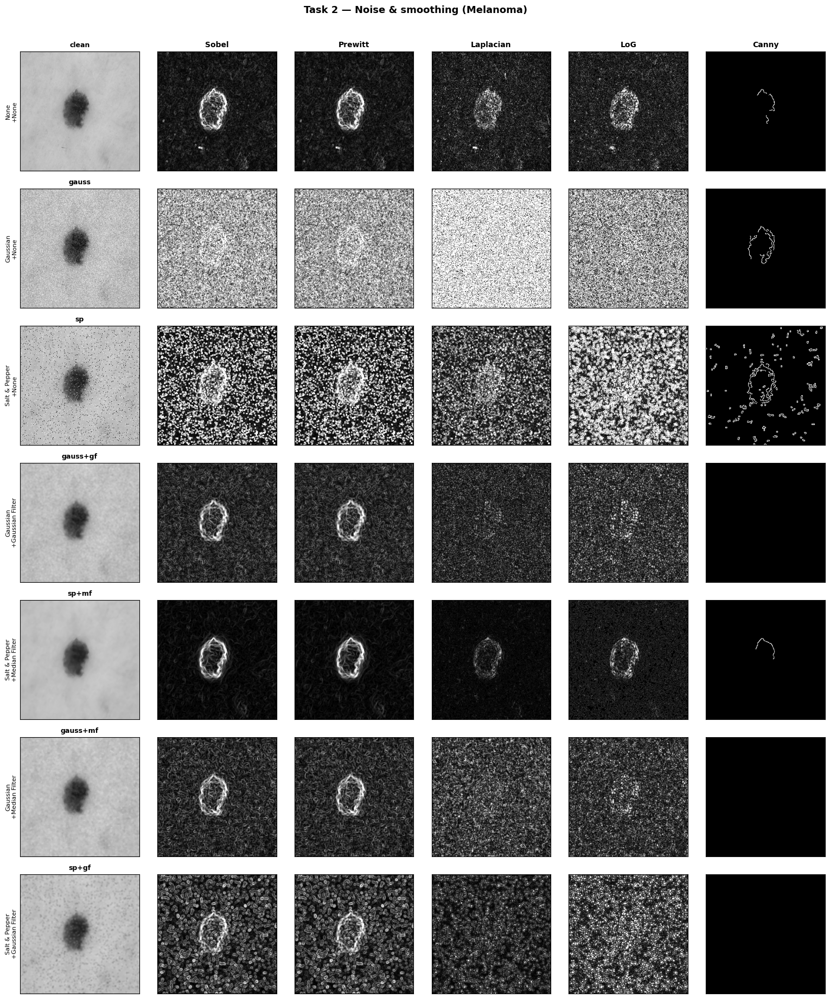

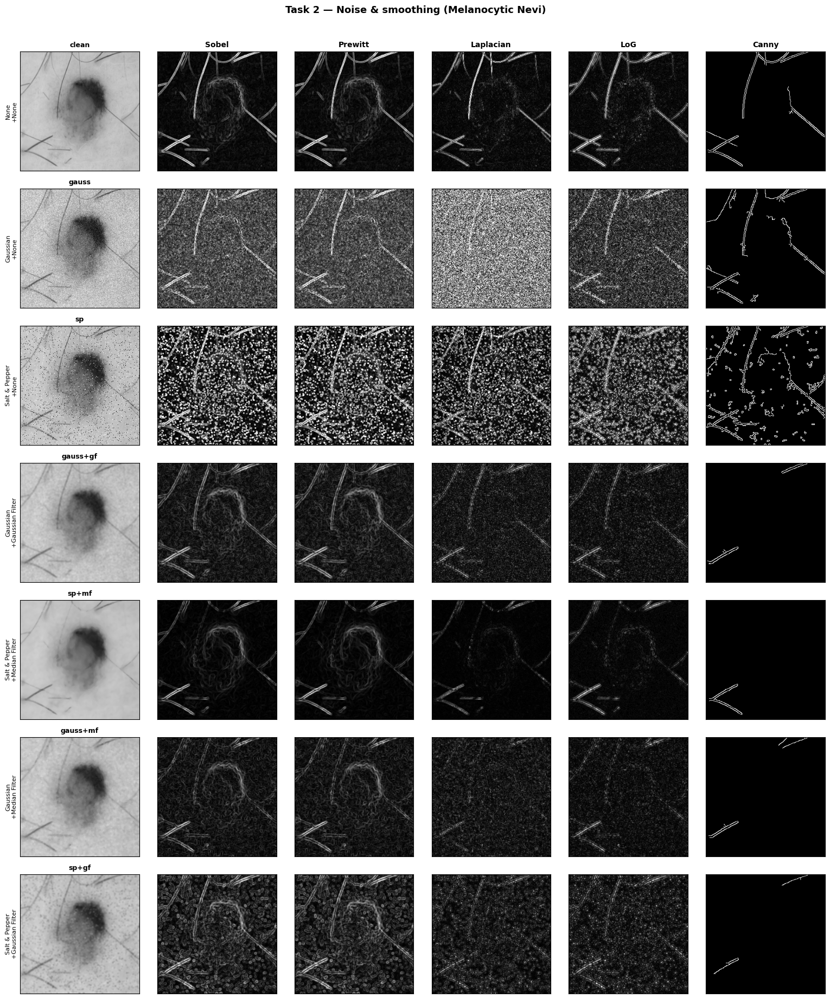

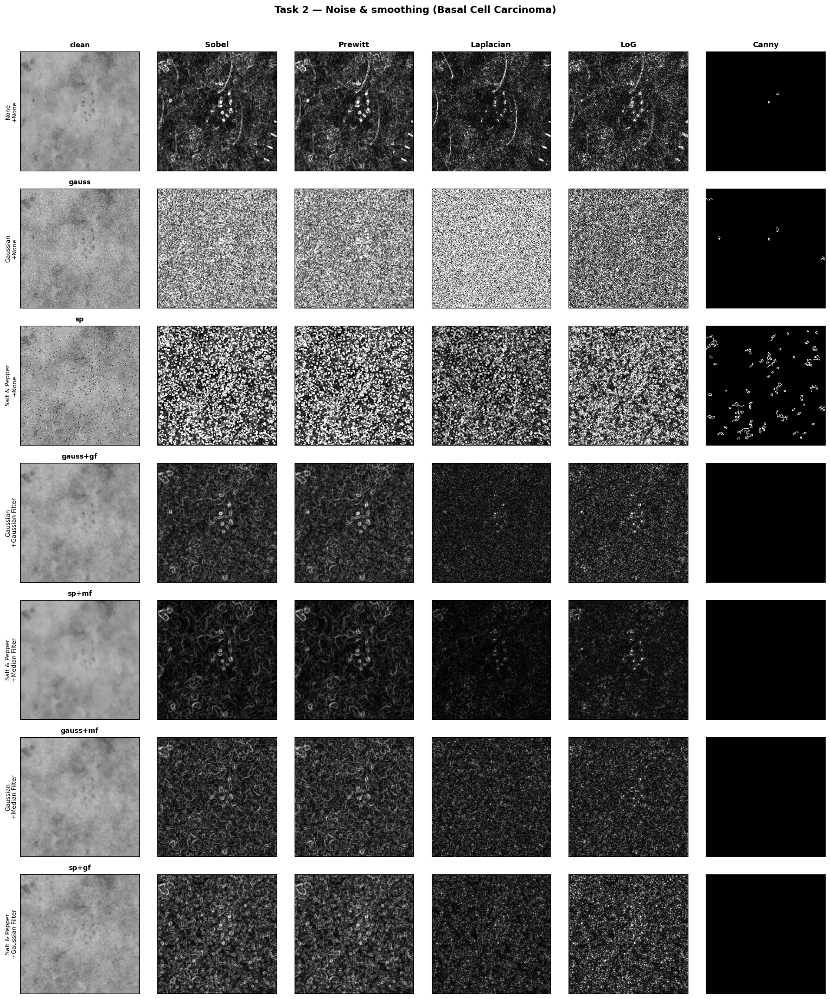

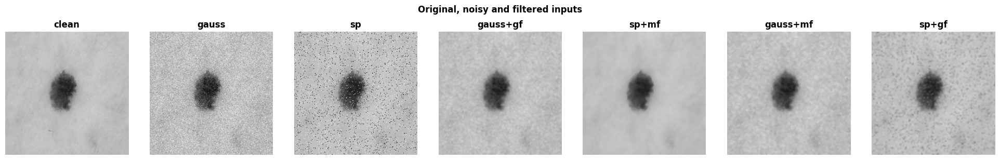

In [7]:
CONDITIONS = {
    "clean":    ("Original", "None",          "None"),
    "gauss":    ("Noisy",    "Gaussian",      "None"),
    "sp":       ("Noisy",    "Salt & Pepper", "None"),
    "gauss+gf": ("Noisy",    "Gaussian",      "Gaussian Filter"),
    "sp+mf":    ("Noisy",    "Salt & Pepper", "Median Filter"),
    "gauss+mf": ("Noisy",    "Gaussian",      "Median Filter"),
    "sp+gf":    ("Noisy",    "Salt & Pepper", "Gaussian Filter"),
}

def make_conditions(g, seed=0):
    gn = add_gaussian_noise(g, seed=seed)
    sp = add_salt_pepper(g, seed=seed)
    return {"clean": g, "gauss": gn, "sp": sp,
            "gauss+gf": gaussian_filter(gn), "sp+mf": median_filter(sp),
            "gauss+mf": median_filter(gn), "sp+gf": gaussian_filter(sp)}

# ── Visual comparison for 3 images from different classes ─────────────────────
for c in REQ_CLASSES:
    g = to_gray(load_rgb(sample_rows[c]["path"]))
    conds = make_conditions(g)
    vmax = {d: np.percentile(edge_response(d, g), 99.5) + 1e-8 for d in DETECTORS}
    rows = list(CONDITIONS.keys())
    fig, axes = plt.subplots(len(rows), 1 + len(DETECTORS), figsize=(2.6 * (1 + len(DETECTORS)), 2.6 * len(rows)))
    for i, cond in enumerate(rows):
        img = conds[cond]
        axes[i][0].imshow(img, cmap="gray", vmin=0, vmax=255)
        _, nz, pp = CONDITIONS[cond]
        axes[i][0].set_ylabel(f"{nz}\n+{pp}", fontsize=8)
        axes[i][0].set_title(f"{cond}", fontsize=9, fontweight="bold")
        for j, d in enumerate(DETECTORS, start=1):
            # same display scale as the clean image → noise differences are visible
            axes[i][j].imshow(to_display(edge_response(d, img), vmax[d]), cmap="gray")
            if i == 0: axes[i][j].set_title(d, fontsize=10, fontweight="bold")
        for a in axes[i]: a.set_xticks([]); a.set_yticks([])
    plt.suptitle(f"Task 2 — Noise & smoothing ({CLASS_FULL.get(c, c)})", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/task2_noise_{c}.png", dpi=130, bbox_inches="tight"); plt.show()

# ── Noisy / filtered input images side by side ────────────────────────────────
g = to_gray(load_rgb(sample_rows[REQ_CLASSES[0]]["path"])); conds = make_conditions(g)
fig, axes = plt.subplots(1, len(conds), figsize=(2.8 * len(conds), 3))
for a, (k, v) in zip(axes, conds.items()):
    a.imshow(v, cmap="gray", vmin=0, vmax=255); a.set_title(k, fontweight="bold"); a.axis("off")
plt.suptitle("Original, noisy and filtered inputs", fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task2_inputs.png", dpi=130, bbox_inches="tight"); plt.show()

Task 2 images:   0%|          | 0/14 [00:00<?, ?it/s]

TABLE 1 — Effect of Noise and Preprocessing on Edge Detection (mean of 14 images)


,Edge Detector,Input Image,Noise Type,Preprocessing,Edge Quality,Noise Sensitivity,Observations
0,Sobel,Original,None,None,Moderate (seg 17px),High (66% inherent),"Continuity 17 px/segment, 573 fragments, density 10.0%. Reference map; under unfiltered noise 66% of its edges becom..."
1,Sobel,Noisy,Gaussian,None,"Poor (F1 0.44, 8.0× edges)",High (72% false),"Continuity 27265 px/segment, 108 fragments, density 79.8% (8.0× the clean edge count); false edges 72%, broken/misse..."
2,Sobel,Noisy,Salt & Pepper,None,"Poor (F1 0.56, 3.9× edges)",High (61% false),"Continuity 43 px/segment, 607 fragments, density 39.4% (3.9× the clean edge count); false edges 61%, broken/missed e..."
3,Sobel,Noisy,Gaussian,Gaussian Filter,"Moderate (F1 0.62, 1.5× edges)",Medium (36% false),"Continuity 15 px/segment, 668 fragments, density 15.3% (1.5× the clean edge count); false edges 36%, broken/missed e..."
4,Sobel,Noisy,Salt & Pepper,Median Filter,"Moderate (F1 0.63, 0.3× edges)",Low (0% false),"Continuity 26 px/segment, 111 fragments, density 3.2% (0.3× the clean edge count); false edges 0%, broken/missed edg..."
5,Prewitt,Original,None,None,Moderate (seg 17px),High (67% inherent),"Continuity 17 px/segment, 562 fragments, density 10.0%. Reference map; under unfiltered noise 67% of its edges becom..."
6,Laplacian,Original,None,None,Poor (seg 5px),High (51% inherent),"Continuity 5 px/segment, 1775 fragments, density 10.7%. Reference map; under unfiltered noise 51% of its edges becom..."
7,LoG,Noisy,Gaussian,Gaussian Filter,"Moderate (F1 0.67, 1.5× edges)",Medium (36% false),"Continuity 7 px/segment, 1846 fragments, density 20.0% (1.5× the clean edge count); false edges 36%, broken/missed e..."
8,Canny,Original,None,Built-in smoothing,Good (seg 41px),High (69% inherent),"Continuity 41 px/segment, 4 fragments, density 0.6%. Reference map; under unfiltered noise 69% of its edges become f..."
9,Canny,Noisy,Gaussian,Gaussian Filter,"Moderate (F1 0.66, 0.3× edges)",Medium (25% false),"Continuity 37 px/segment, 1 fragments, density 0.2% (0.3× the clean edge count); false edges 25%, broken/missed edge..."



Extended grid — F1 vs clean edge map (all detectors × all conditions)


cond,clean,gauss,sp,gauss+gf,sp+mf,gauss+mf,sp+gf
detector,,,,,,,
Sobel,1.0,0.441,0.562,0.621,0.633,0.564,0.516
Prewitt,1.0,0.438,0.558,0.627,0.640,0.567,0.517
Laplacian,1.0,0.585,0.726,0.349,0.280,0.560,0.442
LoG,1.0,0.642,0.660,0.674,0.552,0.623,0.637
Canny,1.0,0.604,0.121,0.659,0.698,0.664,0.651


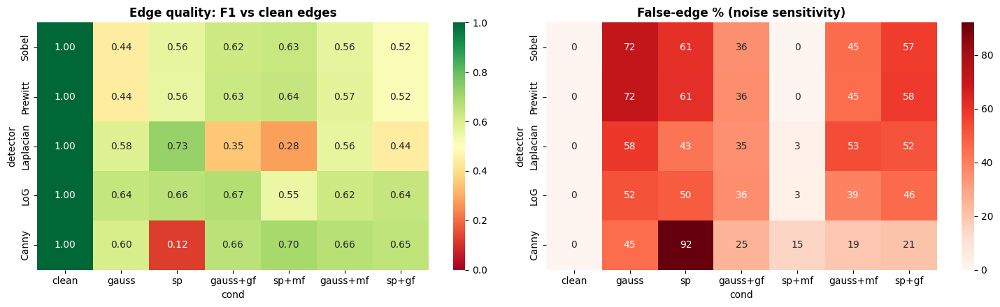

In [8]:
# ── Quantitative evaluation over several images (2 per class) ────────────────
N_PER_CLASS_T2 = 2
t2_rows = pd.concat([train_df[train_df["dx"] == c].sample(min(N_PER_CLASS_T2, (train_df["dx"] == c).sum()),
                                                            random_state=SEED) for c in CLASSES])
records = []
for k, (_, row) in enumerate(tqdm(list(t2_rows.iterrows()), desc="Task 2 images")):
    g = to_gray(load_rgb(row["path"]))
    conds = make_conditions(g, seed=k)
    for d in DETECTORS:
        if d == "Canny":
            ref = (canny(g) > 0).astype(np.uint8); thr = None
        else:
            clean_resp = GRAD_DETECTORS[d](g)
            thr = np.percentile(clean_resp, 90)      # threshold fixed on the clean image
            ref = binarize(clean_resp, thr)
        for cond, img in conds.items():
            e = (canny(img) > 0).astype(np.uint8) if d == "Canny" else binarize(GRAD_DETECTORS[d](img), thr)
            st, cp = edge_stats(e), compare_edges(e, ref)
            records.append(dict(detector=d, cond=cond, **st, **cp))

t2 = pd.DataFrame(records).groupby(["detector", "cond"]).mean(numeric_only=True).reset_index()
clean_density = t2[t2["cond"] == "clean"].set_index("detector")["density"]
t2["density_ratio"] = t2["density"] / t2["detector"].map(clean_density).clip(lower=1e-6)

# Inherent noise sensitivity of each detector = mean false-edge % on unfiltered noisy input
inherent = (t2[t2["cond"].isin(["gauss", "sp"])].groupby("detector")["false_pct"].mean())

def sens_label(p):  return "Low" if p < 25 else ("Medium" if p < 50 else "High")
def qual_label_noisy(f1, dens_ratio):
    if dens_ratio > 3:            # edge map flooded by noise → cluttered, unusable
        return "Poor"
    return "Good" if f1 >= 0.75 else ("Moderate" if f1 >= 0.50 else "Poor")
def qual_label_clean(seg): return "Good" if seg >= 25 else ("Moderate" if seg >= 10 else "Poor")

def observation(r):
    d, cond = r["detector"], r["cond"]
    base = f"Continuity {r['seg_len']:.0f} px/segment, {r['fragments']:.0f} fragments, density {100*r['density']:.1f}%"
    if cond == "clean":
        return base + f". Reference map; under unfiltered noise {inherent[d]:.0f}% of its edges become false edges."
    txt = base + (f" ({r['density_ratio']:.1f}× the clean edge count); false edges {r['false_pct']:.0f}%, "
                  f"broken/missed edges {r['missed_pct']:.0f}%, F1 vs clean {r['f1']:.2f}")
    if cond in ("gauss+gf", "sp+mf", "gauss+mf", "sp+gf"):
        raw_cond = cond.split("+")[0]
        before = t2[(t2.detector == d) & (t2.cond == raw_cond)].iloc[0]
        txt += (f". Smoothing reduced false edges {before['false_pct']:.0f}% → {r['false_pct']:.0f}% "
                f"and changed F1 {before['f1']:.2f} → {r['f1']:.2f}")
    return txt + "."

def build_row(r):
    inp, nz, pp = CONDITIONS[r["cond"]]
    if r["detector"] == "Canny" and r["cond"] == "clean":
        pp = "Built-in smoothing"
    if r["cond"] == "clean":
        q = f"{qual_label_clean(r['seg_len'])} (seg {r['seg_len']:.0f}px)"
        s = f"{sens_label(inherent[r['detector']])} ({inherent[r['detector']]:.0f}% inherent)"
    else:
        q = f"{qual_label_noisy(r['f1'], r['density_ratio'])} (F1 {r['f1']:.2f}, {r['density_ratio']:.1f}× edges)"
        s = f"{sens_label(r['false_pct'])} ({r['false_pct']:.0f}% false)"
    return {"Edge Detector": r["detector"], "Input Image": inp, "Noise Type": nz, "Preprocessing": pp,
            "Edge Quality": q, "Noise Sensitivity": s, "Observations": observation(r)}

t2_full = pd.DataFrame([build_row(r) for _, r in t2.iterrows()])
t2_full["_c"] = t2["cond"].values

REQUIRED_T1 = [("Sobel", "clean"), ("Sobel", "gauss"), ("Sobel", "sp"), ("Sobel", "gauss+gf"), ("Sobel", "sp+mf"),
               ("Prewitt", "clean"), ("Laplacian", "clean"), ("LoG", "gauss+gf"),
               ("Canny", "clean"), ("Canny", "gauss+gf"), ("Canny", "sp+mf")]
table1 = pd.concat([t2_full[(t2_full["Edge Detector"] == d) & (t2_full["_c"] == c)] for d, c in REQUIRED_T1])
table1 = table1.drop(columns="_c").reset_index(drop=True)

print("TABLE 1 — Effect of Noise and Preprocessing on Edge Detection (mean of", len(t2_rows), "images)")
display(table1)
table1.to_csv(f"{RESULTS_DIR}/table1_noise_preprocessing.csv", index=False)

numeric_t2 = t2.pivot(index="detector", columns="cond", values="f1").reindex(DETECTORS)[list(CONDITIONS)]
print("\nExtended grid — F1 vs clean edge map (all detectors × all conditions)")
display(numeric_t2.round(3))
t2_full.drop(columns="_c").to_csv(f"{RESULTS_DIR}/table1_extended_all_conditions.csv", index=False)
t2.to_csv(f"{RESULTS_DIR}/table1_raw_numbers.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(numeric_t2, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax[0])
ax[0].set_title("Edge quality: F1 vs clean edges", fontweight="bold")
fp = t2.pivot(index="detector", columns="cond", values="false_pct").reindex(DETECTORS)[list(CONDITIONS)]
sns.heatmap(fp, annot=True, fmt=".0f", cmap="Reds", ax=ax[1])
ax[1].set_title("False-edge % (noise sensitivity)", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task2_quality_heatmaps.png", dpi=150, bbox_inches="tight"); plt.show()

## 🎚️ Section 8 — Task 3: Canny Parameter Analysis
*Kernel size* = size of the Gaussian smoothing kernel applied before Canny's gradient step.

**Automatic selection of the most useful configuration.** For skin lesions the useful edge map keeps the lesion border and major internal structures while ignoring skin texture/noise. Each configuration is scored with:
* **Stability** – F1 between the edge map of the clean image and of the Gaussian-noisy image (robustness)
* **Continuity** – mean connected-segment length
* **Density penalty** – configurations that keep < 1 % or > 12 % of pixels as edges are penalised (too empty / too cluttered)

`score = stability × log(1 + continuity) × density_penalty`

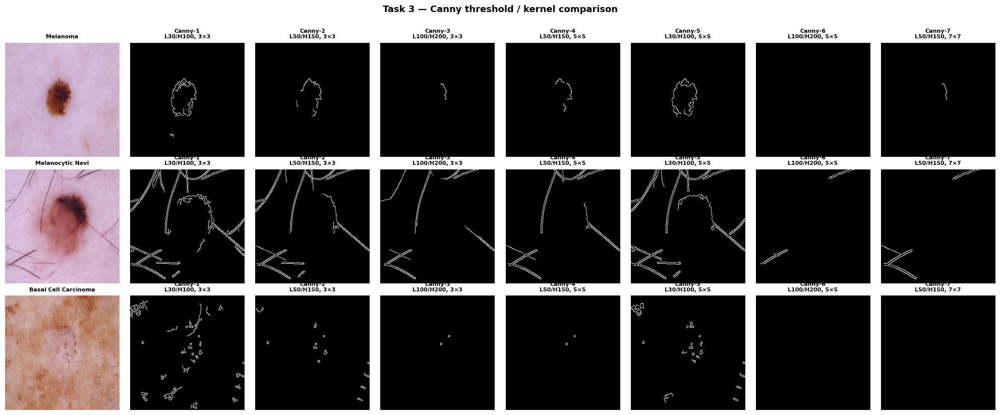

Task 3 images:   0%|          | 0/21 [00:00<?, ?it/s]

TABLE 2 — Canny Parameter Analysis (mean of 21 images)


,Configuration,Low Threshold,High Threshold,Kernel Size,Edge Quality,Number of Detected Edges,Observation
0,Canny-1,30,100,3×3,Poor,1600 px / 24 segments,2.4% edge pixels in 24 segments (mean 60px); noise stability F1 0.14; score 0.59
1,Canny-2,50,150,3×3,Poor,566 px / 8 segments,0.9% edge pixels in 8 segments (mean 51px); noise stability F1 0.21; score 0.40
2,Canny-3,100,200,3×3,Moderate,165 px / 4 segments,0.3% edge pixels in 4 segments (mean 27px); noise stability F1 0.62; score 1.03
3,Canny-4,50,150,5×5,Good,311 px / 5 segments,0.5% edge pixels in 5 segments (mean 38px); noise stability F1 0.60; score 1.10
4,Canny-5,30,100,5×5,Moderate,939 px / 14 segments,1.4% edge pixels in 14 segments (mean 56px); noise stability F1 0.25; score 1.00
5,Canny-6,100,200,5×5,Poor,72 px / 1 segments,0.1% edge pixels in 1 segments (mean 16px); noise stability F1 0.71; score 1.00
6,Canny-7,50,150,7×7,Good,114 px / 1 segments,0.2% edge pixels in 1 segments (mean 31px); noise stability F1 0.70; score 1.21 ← SELECTED



🏆 Selected edge representation: Canny-7  (Low=50, High=150, Gaussian 7×7)


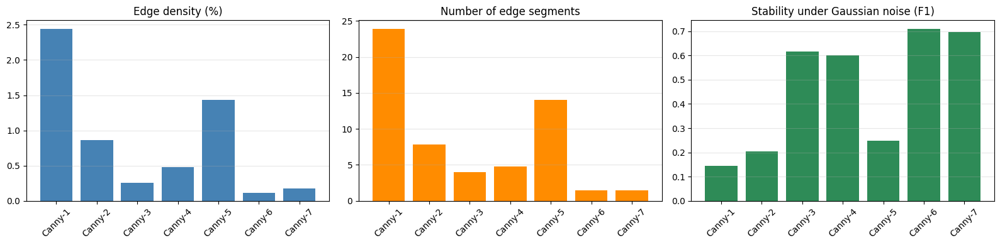

In [9]:
CANNY_CONFIGS = [
    ("Canny-1",  30, 100, 3),
    ("Canny-2",  50, 150, 3),
    ("Canny-3", 100, 200, 3),
    ("Canny-4",  50, 150, 5),
    ("Canny-5",  30, 100, 5),
    ("Canny-6", 100, 200, 5),
    ("Canny-7",  50, 150, 7),
]

# visual comparison
fig, axes = plt.subplots(len(REQ_CLASSES), len(CANNY_CONFIGS) + 1, figsize=(2.5 * (len(CANNY_CONFIGS) + 1), 2.7 * len(REQ_CLASSES)))
for i, c in enumerate(REQ_CLASSES):
    rgb = load_rgb(sample_rows[c]["path"]); g = to_gray(rgb)
    axes[i][0].imshow(rgb); axes[i][0].set_title(CLASS_FULL.get(c, c), fontsize=8, fontweight="bold")
    for j, (nm, lo, hi, k) in enumerate(CANNY_CONFIGS, start=1):
        axes[i][j].imshow(canny(g, lo, hi, k), cmap="gray")
        axes[i][j].set_title(f"{nm}\nL{lo}/H{hi}, {k}×{k}", fontsize=8, fontweight="bold")
    for a in axes[i]: a.axis("off")
plt.suptitle("Task 3 — Canny threshold / kernel comparison", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task3_canny_configs.png", dpi=140, bbox_inches="tight"); plt.show()

# quantitative analysis (3 images per class)
t3_rows = pd.concat([train_df[train_df["dx"] == c].sample(min(3, (train_df["dx"] == c).sum()), random_state=SEED + 1)
                     for c in CLASSES])
rec3 = []
for k, (_, row) in enumerate(tqdm(list(t3_rows.iterrows()), desc="Task 3 images")):
    g  = to_gray(load_rgb(row["path"]))
    gn = add_gaussian_noise(g, seed=100 + k)
    for nm, lo, hi, ks in CANNY_CONFIGS:
        e  = (canny(g, lo, hi, ks) > 0).astype(np.uint8)
        en = (canny(gn, lo, hi, ks) > 0).astype(np.uint8)
        rec3.append(dict(config=nm, **edge_stats(e), stability=compare_edges(en, e)["f1"]))
t3 = pd.DataFrame(rec3).groupby("config").mean(numeric_only=True).reindex([c[0] for c in CANNY_CONFIGS])

def density_penalty(d): return 1.0 if 0.01 <= d <= 0.12 else 0.5
t3["score"] = t3["stability"] * np.log1p(t3["seg_len"]) * t3["density"].apply(density_penalty)
rank = t3["score"].rank(ascending=False)
n_cfg = len(t3)
t3["quality"] = ["Good" if r <= n_cfg / 3 else ("Moderate" if r <= 2 * n_cfg / 3 else "Poor") for r in rank]

BEST_CANNY = t3["score"].idxmax()
_cfg = {c[0]: c for c in CANNY_CONFIGS}
_, BEST_LOW, BEST_HIGH, BEST_K = _cfg[BEST_CANNY]

rows2 = []
for nm, lo, hi, ks in CANNY_CONFIGS:
    r = t3.loc[nm]
    obs = (f"{100*r['density']:.1f}% edge pixels in {r['fragments']:.0f} segments (mean {r['seg_len']:.0f}px); "
           f"noise stability F1 {r['stability']:.2f}; score {r['score']:.2f}")
    if nm == BEST_CANNY: obs += "  ← SELECTED"
    rows2.append({"Configuration": nm, "Low Threshold": lo, "High Threshold": hi, "Kernel Size": f"{ks}×{ks}",
                  "Edge Quality": r["quality"], "Number of Detected Edges": f"{r['pixels']:.0f} px / {r['fragments']:.0f} segments",
                  "Observation": obs})
table2 = pd.DataFrame(rows2)
print("TABLE 2 — Canny Parameter Analysis (mean of", len(t3_rows), "images)")
display(table2)
table2.to_csv(f"{RESULTS_DIR}/table2_canny_parameters.csv", index=False)
print(f"\n🏆 Selected edge representation: {BEST_CANNY}  (Low={BEST_LOW}, High={BEST_HIGH}, Gaussian {BEST_K}×{BEST_K})")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(t3.index, 100 * t3["density"], color="steelblue"); ax[0].set_title("Edge density (%)")
ax[1].bar(t3.index, t3["fragments"], color="darkorange"); ax[1].set_title("Number of edge segments")
ax[2].bar(t3.index, t3["stability"], color="seagreen"); ax[2].set_title("Stability under Gaussian noise (F1)")
for a in ax: a.tick_params(axis="x", rotation=45); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task3_canny_stats.png", dpi=150, bbox_inches="tight"); plt.show()

## 🗂️ Section 9 — Task 4: Set A (Raw), Set B (Filtered), Set C (Edge)
* **Set A — Raw:** original RGB images (Lab 01)
* **Set B — Filtered:** `BEST_FILTER` from Lab 02 (Sharpening)
* **Set C — Edge:** best Canny configuration from Task 3, binary map replicated to 3 channels

Same train / validation / test indices, epochs and metrics for all three sets.

## ⚡ Section 10 — Apply Filters & Edge Detection ONCE (cache before training)
Every image is read **once**, the filter and edge detector are applied **once**, and the results are stored as `uint8` arrays in RAM **and** in `lab03_cache/`. If the kernel restarts, re-running this cell loads the cache in seconds instead of recomputing.

Filtering + edges (train):   0%|          | 0/7210 [00:00<?, ?it/s]

Filtering + edges (val):   0%|          | 0/802 [00:00<?, ?it/s]

Filtering + edges (test):   0%|          | 0/2003 [00:00<?, ?it/s]

✅ All three sets ready in 131s — no image loading/filtering during training
  Raw       CNN train (7210, 160, 160, 3)   classical train (7210, 64, 64, 3)
  Filtered  CNN train (7210, 160, 160, 3)   classical train (7210, 64, 64, 3)
  Edge      CNN train (7210, 160, 160)   classical train (7210, 64, 64)


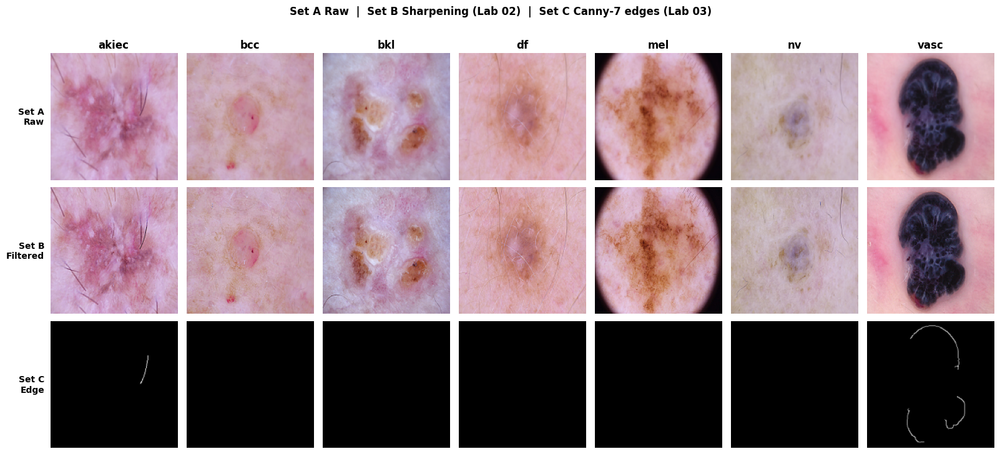

In [10]:
SETS = ["Raw", "Filtered", "Edge"]
CACHE_TAG = f"{BEST_FILTER}_c{BEST_LOW}-{BEST_HIGH}-k{BEST_K}_s{CNN_SIZE}-{CLASSICAL_SIZE}_n{len(df)}"

def build_arrays(frame, desc):
    n = len(frame)
    cnn = {"Raw": np.zeros((n, CNN_SIZE, CNN_SIZE, 3), np.uint8),
           "Filtered": np.zeros((n, CNN_SIZE, CNN_SIZE, 3), np.uint8),
           "Edge": np.zeros((n, CNN_SIZE, CNN_SIZE), np.uint8)}
    cls = {"Raw": np.zeros((n, CLASSICAL_SIZE, CLASSICAL_SIZE, 3), np.uint8),
           "Filtered": np.zeros((n, CLASSICAL_SIZE, CLASSICAL_SIZE, 3), np.uint8),
           "Edge": np.zeros((n, CLASSICAL_SIZE, CLASSICAL_SIZE), np.uint8)}
    for i, p in enumerate(tqdm(frame["path"].values, desc=desc)):
        rgb  = load_rgb(p, ANALYSIS_SIZE)
        filt = apply_filter(rgb, BEST_FILTER)                  # Lab 02 filter  → Set B
        edge = canny(to_gray(rgb), BEST_LOW, BEST_HIGH, BEST_K)  # Lab 03 edges → Set C
        for s, im in (("Raw", rgb), ("Filtered", filt), ("Edge", edge)):
            cnn[s][i] = cv2.resize(im, (CNN_SIZE, CNN_SIZE), interpolation=cv2.INTER_AREA)
            cls[s][i] = cv2.resize(im, (CLASSICAL_SIZE, CLASSICAL_SIZE), interpolation=cv2.INTER_AREA)
    return cnn, cls

def cache_file(split, kind, s): return os.path.join(CACHE_DIR, f"{CACHE_TAG}_{split}_{kind}_{s}.npy")

t0 = time.time()
CNN_DATA, CLS_DATA = {}, {}
for split, frame in (("train", train_df), ("val", val_df), ("test", test_df)):
    files = [cache_file(split, k, s) for k in ("cnn", "cls") for s in SETS]
    if all(os.path.exists(f) for f in files):
        CNN_DATA[split] = {s: np.load(cache_file(split, "cnn", s)) for s in SETS}
        CLS_DATA[split] = {s: np.load(cache_file(split, "cls", s)) for s in SETS}
        print(f"♻️  {split}: loaded from cache")
    else:
        CNN_DATA[split], CLS_DATA[split] = build_arrays(frame, f"Filtering + edges ({split})")
        for s in SETS:
            np.save(cache_file(split, "cnn", s), CNN_DATA[split][s])
            np.save(cache_file(split, "cls", s), CLS_DATA[split][s])
Y = {"train": train_df["label"].values, "val": val_df["label"].values, "test": test_df["label"].values}
print(f"✅ All three sets ready in {time.time() - t0:.0f}s — no image loading/filtering during training")
for s in SETS:
    print(f"  {s:9s} CNN train {CNN_DATA['train'][s].shape}   classical train {CLS_DATA['train'][s].shape}")

fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(2.3 * NUM_CLASSES, 7.2))
for j, c in enumerate(CLASSES):
    hits = np.where(Y["train"] == cls2idx[c])[0]
    for i, s in enumerate(SETS):
        axes[i][j].axis("off")
        if len(hits) == 0: continue
        im = CNN_DATA["train"][s][hits[0]]
        axes[i][j].imshow(im, cmap="gray" if im.ndim == 2 else None)
        if i == 0: axes[i][j].set_title(c, fontweight="bold")
for i, s in enumerate(SETS):
    axes[i][0].text(-8, CNN_SIZE / 2, f"Set {'ABC'[i]}\n{s}", ha="right", va="center", fontweight="bold")
plt.suptitle(f"Set A Raw  |  Set B {BEST_FILTER.title()} (Lab 02)  |  Set C {BEST_CANNY} edges (Lab 03)", fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task4_three_sets.png", dpi=140, bbox_inches="tight"); plt.show()

## 🤖 Section 11 — Task 5 (part 1): Classical Classifiers — SVM · Random Forest · KNN
Input: 64×64 image flattened → StandardScaler → PCA(100) → classifier. Class imbalance is handled with `class_weight="balanced"` (SVM, RF) and distance-weighted voting (KNN).
Metrics are **weighted** averages (same convention as Lab 01); macro-F1 and balanced accuracy are also stored.

In [11]:
RESULTS = {}      # (model, set) → dict of metrics + predictions

def compute_metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, average="weighted", zero_division=0),
                recall=recall_score(y_true, y_pred, average="weighted", zero_division=0),
                f1=f1_score(y_true, y_pred, average="weighted", zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average="macro", zero_division=0),
                balanced_acc=balanced_accuracy_score(y_true, y_pred))

def classical_models():
    return {
        "SVM": SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED),
        "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1),
    }

def flat(split, s):
    X = CLS_DATA[split][s]
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

for s in SETS:
    Xtr, Xte = flat("train", s), flat("test", s)
    n_comp = min(PCA_DIM, Xtr.shape[0] - 1, Xtr.shape[1])
    for name, clf in classical_models().items():
        pipe = make_pipeline(StandardScaler(), PCA(n_components=n_comp, random_state=SEED), clf)
        t0 = time.time(); pipe.fit(Xtr, Y["train"]); train_t = time.time() - t0
        t0 = time.time(); pred = pipe.predict(Xte); infer_ms = (time.time() - t0) / len(Xte) * 1000
        m = compute_metrics(Y["test"], pred)
        RESULTS[(name, s)] = dict(**m, train_time=train_t, infer_ms=infer_ms, y_pred=pred)
        print(f"{name:14s} | {s:8s} | Acc {m['accuracy']:.4f}  F1 {m['f1']:.4f}  macroF1 {m['macro_f1']:.4f} "
              f"| train {train_t:6.1f}s | infer {infer_ms:.3f} ms/img")
print("✅ Classical classifiers done")

SVM            | Raw      | Acc 0.6750  F1 0.6940  macroF1 0.4703 | train   14.4s | infer 0.708 ms/img
Random Forest  | Raw      | Acc 0.6710  F1 0.5404  macroF1 0.1200 | train   31.7s | infer 0.235 ms/img
KNN            | Raw      | Acc 0.6975  F1 0.6483  macroF1 0.2698 | train    8.5s | infer 0.204 ms/img
SVM            | Filtered | Acc 0.6740  F1 0.6930  macroF1 0.4638 | train   13.7s | infer 0.690 ms/img
Random Forest  | Filtered | Acc 0.6700  F1 0.5381  macroF1 0.1174 | train   33.8s | infer 0.173 ms/img
KNN            | Filtered | Acc 0.6980  F1 0.6496  macroF1 0.2741 | train    7.8s | infer 0.190 ms/img
SVM            | Edge     | Acc 0.6241  F1 0.5580  macroF1 0.1727 | train   15.7s | infer 0.935 ms/img
Random Forest  | Edge     | Acc 0.6690  F1 0.5383  macroF1 0.1159 | train    9.0s | infer 0.128 ms/img
KNN            | Edge     | Acc 0.6605  F1 0.5621  macroF1 0.1687 | train    4.0s | infer 0.125 ms/img
✅ Classical classifiers done


## 🧠 Section 12 — Task 5 (part 2): CNN Models (Lab 02 architectures)
* **CNN Model 1 — EfficientNet-B3** and **CNN Model 2 — ResNet-50**, with the exact Lab 02 heads (Dropout 0.4 → Linear 512 → ReLU → Dropout 0.3 → Linear 7).
* Same Lab 02 training recipe: AdamW (lr 1e-4, wd 1e-4), cosine LR, class-weighted cross-entropy with label smoothing 0.1, class-balanced sampling, mixed precision.
* ImageNet weights come from the **in-memory copy** made in Section 3 — nothing is downloaded here.
* Images come from the **pre-computed cache** — augmentation (flips / 90° rotations) is done on the GPU.
* Best epoch selected on **validation macro-F1**, then evaluated once on the **test set**.

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEVICE)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEVICE)

def to_tensor_batch(arr):
    t = torch.from_numpy(np.ascontiguousarray(arr)).to(DEVICE, non_blocking=True)
    t = t.unsqueeze(1).repeat(1, 3, 1, 1) if t.ndim == 3 else t.permute(0, 3, 1, 2)
    return (t.float() / 255.0 - MEAN) / STD

def lab2_head(in_f):
    return nn.Sequential(nn.Dropout(0.4), nn.Linear(in_f, 512), nn.ReLU(),
                         nn.Dropout(0.3), nn.Linear(512, NUM_CLASSES))

def build_model(name):
    # Architecture is created empty and filled from the weights downloaded ONCE in Section 3
    if name == "efficientnet_b3":
        m = efficientnet_b3(weights=None)
        if PRETRAINED_WEIGHTS[name] is not None: m.load_state_dict(PRETRAINED_WEIGHTS[name])
        m.classifier = lab2_head(m.classifier[1].in_features)
    elif name == "resnet50":
        m = resnet50(weights=None)
        if PRETRAINED_WEIGHTS[name] is not None: m.load_state_dict(PRETRAINED_WEIGHTS[name])
        m.fc = lab2_head(m.fc.in_features)
    else:
        raise ValueError(name)
    return m.to(DEVICE)

CNN_SPECS = {"CNN Model 1 (EfficientNet-B3)": "efficientnet_b3",
             "CNN Model 2 (ResNet-50)":       "resnet50"}

# class weights (Lab 02 formula) + class-balanced sampling probabilities (Lab 02 sampler)
counts   = np.bincount(Y["train"], minlength=NUM_CLASSES).astype(float)
cw       = 1.0 / np.maximum(counts, 1); cw = cw / cw.sum() * NUM_CLASSES
CLASS_W  = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
SAMPLE_P = (1.0 / np.maximum(counts, 1))[Y["train"]]; SAMPLE_P /= SAMPLE_P.sum()

try:
    make_scaler = lambda: torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP); make_scaler()
except Exception:
    make_scaler = lambda: torch.cuda.amp.GradScaler(enabled=USE_AMP)

def train_batches(X, y):
    idx = np.random.choice(len(X), size=len(X), replace=True, p=SAMPLE_P)   # balanced sampler
    for i in range(0, len(idx), BATCH_SIZE):
        b = np.sort(idx[i:i + BATCH_SIZE])
        xb = to_tensor_batch(X[b]); yb = torch.from_numpy(y[b]).long().to(DEVICE)
        if random.random() < 0.5: xb = xb.flip(3)
        if random.random() < 0.5: xb = xb.flip(2)
        k = random.randint(0, 3)
        if k: xb = torch.rot90(xb, k, dims=(2, 3))
        yield xb, yb

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out.append(model(to_tensor_batch(X[i:i + bs])).argmax(1).cpu().numpy())
    return np.concatenate(out)

def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

HISTORIES, TRAINED = {}, {}

def train_cnn(arch, s):
    set_seed()
    model = build_model(arch)
    crit  = nn.CrossEntropyLoss(weight=CLASS_W, label_smoothing=0.1)
    opt   = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = make_scaler()
    Xtr, Xva, Xte = CNN_DATA["train"][s], CNN_DATA["val"][s], CNN_DATA["test"][s]
    hist = dict(loss=[], train_acc=[], val_acc=[], val_f1=[])
    best_f1, best_state = -1, None
    sync(); t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tl = tc = tn = 0
        for xb, yb in train_batches(Xtr, Y["train"]):
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(xb); loss = crit(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        sched.step()
        vp = predict(model, Xva)
        va = accuracy_score(Y["val"], vp); vf = f1_score(Y["val"], vp, average="macro", zero_division=0)
        for k, v in zip(hist, (tl / tn, tc / tn, va, vf)): hist[k].append(v)
        if vf > best_f1:
            best_f1 = vf; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"   Ep {ep:02d}/{EPOCHS} | TrLoss {tl/tn:.4f} TrAcc {tc/tn:.4f} | VlAcc {va:.4f} MacroF1 {vf:.4f}")
    sync(); train_t = time.time() - t0
    model.load_state_dict(best_state)
    sync(); t0 = time.time(); pred = predict(model, Xte); sync()
    infer_ms = (time.time() - t0) / len(Xte) * 1000
    return model, hist, pred, train_t, infer_ms

for disp, arch in CNN_SPECS.items():
    for s in SETS:
        print(f"\n{'─'*60}\n  {disp}  |  Set: {s}\n{'─'*60}")
        model, hist, pred, train_t, infer_ms = train_cnn(arch, s)
        m = compute_metrics(Y["test"], pred)
        RESULTS[(disp, s)] = dict(**m, train_time=train_t, infer_ms=infer_ms, y_pred=pred)
        HISTORIES[(disp, s)] = hist
        if arch == "resnet50" and s == "Raw":
            TRAINED["resnet_raw"] = copy.deepcopy(model).cpu()
        del model
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
        print(f"   TEST → Acc {m['accuracy']:.4f}  P {m['precision']:.4f}  R {m['recall']:.4f}  F1 {m['f1']:.4f}"
              f"  macroF1 {m['macro_f1']:.4f} | train {train_t:.0f}s | infer {infer_ms:.3f} ms/img")
print("\n✅ CNN training complete")


────────────────────────────────────────────────────────────
  CNN Model 1 (EfficientNet-B3)  |  Set: Raw
────────────────────────────────────────────────────────────
   Ep 01/10 | TrLoss 1.0531 TrAcc 0.3422 | VlAcc 0.0985 MacroF1 0.1353
   Ep 02/10 | TrLoss 0.6583 TrAcc 0.5578 | VlAcc 0.1696 MacroF1 0.2394
   Ep 03/10 | TrLoss 0.5712 TrAcc 0.6585 | VlAcc 0.2145 MacroF1 0.2976
   Ep 04/10 | TrLoss 0.5395 TrAcc 0.6818 | VlAcc 0.2344 MacroF1 0.3029
   Ep 05/10 | TrLoss 0.5022 TrAcc 0.7239 | VlAcc 0.2805 MacroF1 0.3519
   Ep 06/10 | TrLoss 0.4801 TrAcc 0.7452 | VlAcc 0.3279 MacroF1 0.3752
   Ep 07/10 | TrLoss 0.4646 TrAcc 0.7642 | VlAcc 0.4352 MacroF1 0.4248
   Ep 08/10 | TrLoss 0.4676 TrAcc 0.7716 | VlAcc 0.4327 MacroF1 0.4263
   Ep 09/10 | TrLoss 0.4635 TrAcc 0.7828 | VlAcc 0.4077 MacroF1 0.4171
   Ep 10/10 | TrLoss 0.4599 TrAcc 0.7770 | VlAcc 0.4701 MacroF1 0.4520
   TEST → Acc 0.4538  P 0.7867  R 0.4538  F1 0.4780  macroF1 0.4449 | train 307s | infer 5.761 ms/img

───────────────────

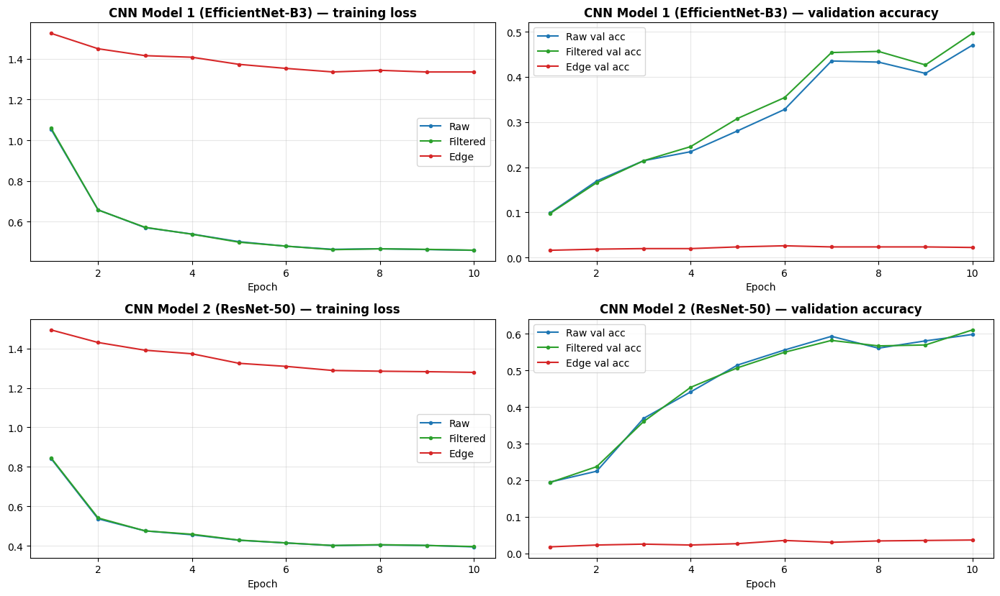

In [13]:
# Training curves
fig, axes = plt.subplots(len(CNN_SPECS), 2, figsize=(14, 4.2 * len(CNN_SPECS)))
axes = np.atleast_2d(axes)
for i, mn in enumerate(CNN_SPECS):
    for s, col in zip(SETS, ["tab:blue", "tab:green", "tab:red"]):
        h = HISTORIES[(mn, s)]; ep = range(1, len(h["loss"]) + 1)
        axes[i][0].plot(ep, h["loss"], "-o", ms=3, color=col, label=s)
        axes[i][1].plot(ep, h["val_acc"], "-o", ms=3, color=col, label=f"{s} val acc")
    axes[i][0].set_title(f"{mn} — training loss", fontweight="bold")
    axes[i][1].set_title(f"{mn} — validation accuracy", fontweight="bold")
    for a in axes[i]: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task5_cnn_curves.png", dpi=150, bbox_inches="tight"); plt.show()

### 📋 Table 3 — Cross-Lab Classification Performance Comparison

In [14]:
MODEL_ORDER = ["SVM", "Random Forest", "KNN"] + list(CNN_SPECS)

def trip(mn, key, fmt="{:.3f}"):
    return " / ".join(fmt.format(RESULTS[(mn, s)][key]) for s in SETS)

rows3 = []
for mn in MODEL_ORDER:
    rows3.append({"Model / Classifier": mn,
                  "Accuracy Raw (Lab 1)": round(RESULTS[(mn, "Raw")]["accuracy"], 4),
                  "Accuracy Filtered (Lab 2)": round(RESULTS[(mn, "Filtered")]["accuracy"], 4),
                  "Accuracy Edge (Lab 3)": round(RESULTS[(mn, "Edge")]["accuracy"], 4),
                  "Precision (R/F/E)": trip(mn, "precision"),
                  "Recall (R/F/E)": trip(mn, "recall"),
                  "F1-Score (R/F/E)": trip(mn, "f1"),
                  "Training Time (s) (R/F/E)": trip(mn, "train_time", "{:.1f}"),
                  "Inference Time (ms) (R/F/E)": trip(mn, "infer_ms", "{:.3f}")})
table3 = pd.DataFrame(rows3)
print("TABLE 3 — Cross-Lab Classification Performance (R = Raw, F = Filtered, E = Edge; weighted P/R/F1, test set)")
display(table3)
table3.to_csv(f"{RESULTS_DIR}/table3_cross_lab.csv", index=False)

long = pd.DataFrame([{"Model": mn, "Set": s, **{k: v for k, v in RESULTS[(mn, s)].items() if k != "y_pred"}}
                     for mn in MODEL_ORDER for s in SETS])
long.to_csv(f"{RESULTS_DIR}/table3_long_format.csv", index=False)
print("\nFull results (long format):")
display(long.round(4))

TABLE 3 — Cross-Lab Classification Performance (R = Raw, F = Filtered, E = Edge; weighted P/R/F1, test set)


,Model / Classifier,Accuracy Raw (Lab 1),Accuracy Filtered (Lab 2),Accuracy Edge (Lab 3),Precision (R/F/E),Recall (R/F/E),F1-Score (R/F/E),Training Time (s) (R/F/E),Inference Time (ms) (R/F/E)
0,SVM,0.6750,0.6740,0.6241,0.723 / 0.722 / 0.523,0.675 / 0.674 / 0.624,0.694 / 0.693 / 0.558,14.4 / 13.7 / 15.7,0.708 / 0.690 / 0.935
1,Random Forest,0.6710,0.6700,0.6690,0.721 / 0.500 / 0.559,0.671 / 0.670 / 0.669,0.540 / 0.538 / 0.538,31.7 / 33.8 / 9.0,0.235 / 0.173 / 0.128
2,KNN,0.6975,0.6980,0.6605,0.631 / 0.631 / 0.525,0.697 / 0.698 / 0.661,0.648 / 0.650 / 0.562,8.5 / 7.8 / 4.0,0.204 / 0.190 / 0.125
3,CNN Model 1 (EfficientNet-B3),0.4538,0.4813,0.0225,0.787 / 0.788 / 0.063,0.454 / 0.481 / 0.022,0.478 / 0.511 / 0.009,307.3 / 239.1 / 252.5,5.761 / 0.693 / 2.046
4,CNN Model 2 (ResNet-50),0.5761,0.5791,0.0459,0.807 / 0.808 / 0.057,0.576 / 0.579 / 0.046,0.609 / 0.610 / 0.039,173.7 / 172.4 / 189.1,0.654 / 0.648 / 0.758



Full results (long format):


,Model,Set,accuracy,precision,recall,f1,macro_f1,balanced_acc,train_time,infer_ms
0,SVM,Raw,0.6750,0.7233,0.6750,0.6940,0.4703,0.4980,14.4443,0.7080
1,SVM,Filtered,0.6740,0.7219,0.6740,0.6930,0.4638,0.4866,13.6687,0.6903
2,SVM,Edge,0.6241,0.5225,0.6241,0.5580,0.1727,0.1726,15.7042,0.9346
3,Random Forest,Raw,0.6710,0.7215,0.6710,0.5404,0.1200,0.1455,31.6858,0.2349
4,Random Forest,Filtered,0.6700,0.4999,0.6700,0.5381,0.1174,0.1442,33.7698,0.1729
5,Random Forest,Edge,0.6690,0.5590,0.6690,0.5383,0.1159,0.1433,9.0325,0.1279
6,KNN,Raw,0.6975,0.6311,0.6975,0.6483,0.2698,0.2564,8.5158,0.2041
7,KNN,Filtered,0.6980,0.6312,0.6980,0.6496,0.2741,0.2606,7.7832,0.1896
8,KNN,Edge,0.6605,0.5246,0.6605,0.5621,0.1687,0.1707,4.0094,0.1250
9,CNN Model 1 (EfficientNet-B3),Raw,0.4538,0.7867,0.4538,0.4780,0.4449,0.7171,307.2622,5.7611


## 📊 Section 13 — Task 6: Visual Comparison for the Best-Performing Model
The best model is chosen automatically as the one with the highest **mean weighted-F1 over the three sets**.

🏆 Best-performing model: SVM


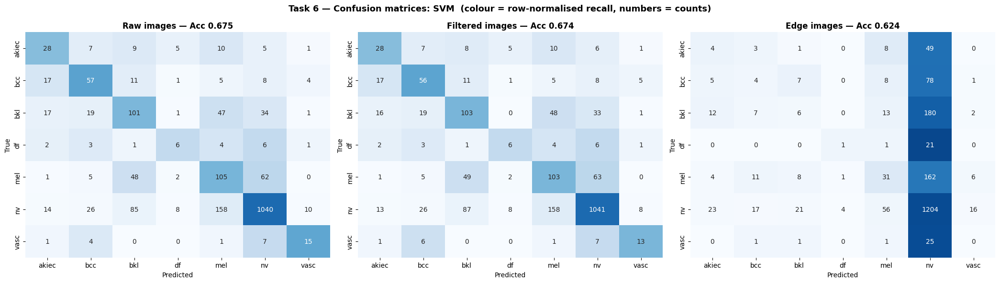

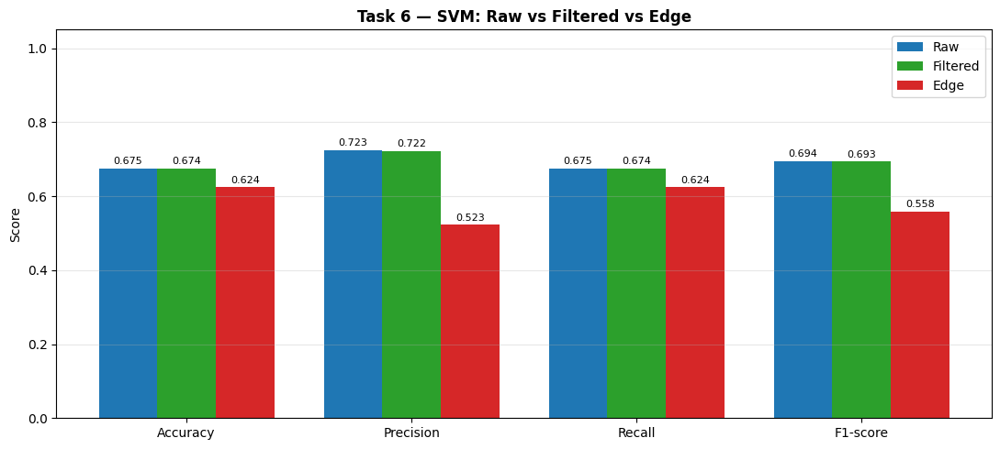

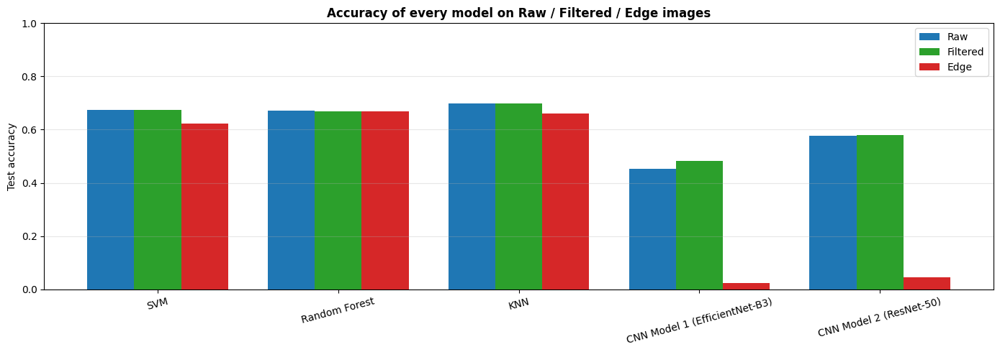

              precision    recall  f1-score   support

       akiec       0.08      0.06      0.07        65
         bcc       0.09      0.04      0.05       103
         bkl       0.14      0.03      0.05       220
          df       0.17      0.04      0.07        23
         mel       0.26      0.14      0.18       223
          nv       0.70      0.90      0.79      1341
        vasc       0.00      0.00      0.00        28

    accuracy                           0.62      2003
   macro avg       0.21      0.17      0.17      2003
weighted avg       0.52      0.62      0.56      2003



In [15]:
BEST_MODEL = max(MODEL_ORDER, key=lambda mn: np.mean([RESULTS[(mn, s)]["f1"] for s in SETS]))
print(f"🏆 Best-performing model: {BEST_MODEL}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for a, s in zip(axes, SETS):
    cm = confusion_matrix(Y["test"], RESULTS[(BEST_MODEL, s)]["y_pred"], labels=range(NUM_CLASSES))
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    sns.heatmap(norm, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES,
                ax=a, cbar=False)
    a.set_title(f"{s} images — Acc {RESULTS[(BEST_MODEL, s)]['accuracy']:.3f}", fontweight="bold")
    a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.suptitle(f"Task 6 — Confusion matrices: {BEST_MODEL}  (colour = row-normalised recall, numbers = counts)",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task6_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

metrics_ = ["accuracy", "precision", "recall", "f1"]
x = np.arange(len(metrics_)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 5))
for i, (s, col) in enumerate(zip(SETS, ["tab:blue", "tab:green", "tab:red"])):
    vals = [RESULTS[(BEST_MODEL, s)][m] for m in metrics_]
    b = ax.bar(x + (i - 1) * w, vals, w, label=s, color=col)
    ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1-score"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.grid(axis="y", alpha=.3); ax.legend()
ax.set_title(f"Task 6 — {BEST_MODEL}: Raw vs Filtered vs Edge", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task6_metric_bars_best_model.png", dpi=150, bbox_inches="tight"); plt.show()

# All models: accuracy per representation
x = np.arange(len(MODEL_ORDER))
fig, ax = plt.subplots(figsize=(14, 5))
for i, (s, col) in enumerate(zip(SETS, ["tab:blue", "tab:green", "tab:red"])):
    ax.bar(x + (i - 1) * w, [RESULTS[(mn, s)]["accuracy"] for mn in MODEL_ORDER], w, label=s, color=col)
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=15)
ax.set_ylim(0, 1); ax.set_ylabel("Test accuracy"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Accuracy of every model on Raw / Filtered / Edge images", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/task6_all_models_accuracy.png", dpi=150, bbox_inches="tight"); plt.show()

print(classification_report(Y["test"], RESULTS[(BEST_MODEL, "Edge")]["y_pred"], labels=range(NUM_CLASSES),
                            target_names=CLASSES, zero_division=0))

## 🔍 Section 14 — Learned vs Hand-crafted Edges (support for Discussion Q6)
The first convolution layer of the ResNet-50 trained on **raw** images is visualised. Many kernels look like oriented edge detectors (Sobel/Prewitt-like), colour-opponent blobs and texture detectors — the network learns edge detectors *plus* colour and texture filters automatically.

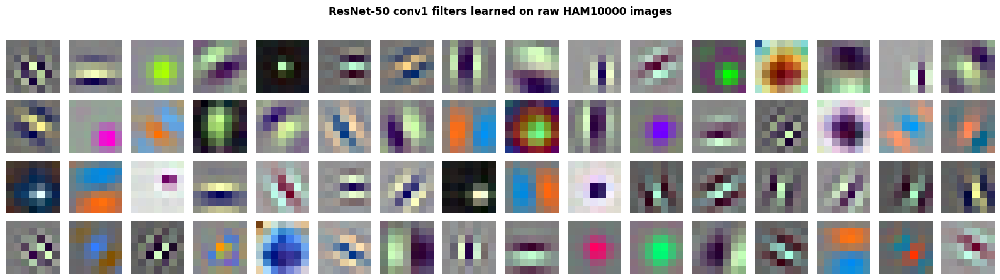

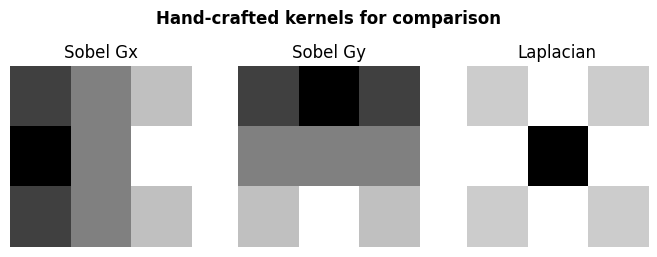

In [16]:
if "resnet_raw" in TRAINED:
    w1 = TRAINED["resnet_raw"].conv1.weight.detach().numpy()          # (64,3,7,7)
    w1 = (w1 - w1.min(axis=(1, 2, 3), keepdims=True)) / (np.ptp(w1, axis=(1, 2, 3), keepdims=True) + 1e-8)
    fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
    for i, a in enumerate(axes.ravel()):
        a.imshow(w1[i].transpose(1, 2, 0)); a.axis("off")
    plt.suptitle("ResNet-50 conv1 filters learned on raw HAM10000 images", fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/q6_learned_conv1_filters.png", dpi=150, bbox_inches="tight"); plt.show()

    fig, ax = plt.subplots(1, 3, figsize=(7, 2.5))
    for a, (k, t) in zip(ax, [(np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]), "Sobel Gx"),
                              (np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]), "Sobel Gy"),
                              (np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]), "Laplacian")]):
        a.imshow(k, cmap="gray"); a.set_title(t); a.axis("off")
    plt.suptitle("Hand-crafted kernels for comparison", fontweight="bold", y=1.01); plt.tight_layout(); plt.show()

## 🧾 Section 15 — Auto-Generated Findings From This Run
This cell reads **your actual numbers** and prints the evidence needed for the discussion questions, so the report can be completed with values from the run.

In [17]:
print("=" * 90)
print("Q1 — Noise sensitivity on unfiltered noisy input (false-edge % | edge-count increase vs clean)")
_dr = t2[t2["cond"].isin(["gauss", "sp"])].pivot(index="detector", columns="cond", values="density_ratio")
_fp = t2[t2["cond"].isin(["gauss", "sp"])].pivot(index="detector", columns="cond", values="false_pct")
for d, v in inherent.sort_values(ascending=False).items():
    print(f"   {d:10s} mean false {v:5.1f}%  | Gaussian: {_fp.loc[d,'gauss']:5.1f}% false, {_dr.loc[d,'gauss']:4.1f}× edges"
          f"  | S&P: {_fp.loc[d,'sp']:5.1f}% false, {_dr.loc[d,'sp']:4.1f}× edges")
most_sens = inherent.idxmax(); least_sens = inherent.idxmin()
print(f"   → Most sensitive: {most_sens};  least sensitive: {least_sens}")

print("\nQ2 — Effect of filtering (F1 vs clean edges)")
for d in DETECTORS:
    r = t2.set_index(["detector", "cond"])["f1"]
    print(f"   {d:10s} Gaussian noise {r[(d,'gauss')]:.2f} → +Gaussian filter {r[(d,'gauss+gf')]:.2f} | "
          f"S&P noise {r[(d,'sp')]:.2f} → +Median {r[(d,'sp+mf')]:.2f} (+Gaussian {r[(d,'sp+gf')]:.2f})")

print("\nQ3 — Canny thresholds")
for nm, lo, hi, ks in CANNY_CONFIGS:
    r = t3.loc[nm]
    print(f"   {nm}  L{lo:3d}/H{hi:3d} k{ks}: density {100*r['density']:5.2f}%  segments {r['fragments']:6.1f}  "
          f"mean length {r['seg_len']:5.1f}px  stability {r['stability']:.2f}")
print(f"   → Selected: {BEST_CANNY}")

print("\nQ4 / Q7 — Accuracy per representation")
acc = pd.DataFrame({s: [RESULTS[(mn, s)]["accuracy"] for mn in MODEL_ORDER] for s in SETS}, index=MODEL_ORDER)
acc["Edge − Raw"] = acc["Edge"] - acc["Raw"]
display(acc.round(4))
mean_acc = acc[SETS].mean()
mean_f1  = pd.Series({s: np.mean([RESULTS[(mn, s)]["f1"] for mn in MODEL_ORDER]) for s in SETS})
mean_mf1 = pd.Series({s: np.mean([RESULTS[(mn, s)]["macro_f1"] for mn in MODEL_ORDER]) for s in SETS})
print("   Mean accuracy :", mean_acc.round(4).to_dict())
print("   Mean wF1      :", mean_f1.round(4).to_dict())
print("   Mean macro-F1 :", mean_mf1.round(4).to_dict())
n_drop = int((acc["Edge − Raw"] < 0).sum())
print(f"   → Edge images reduced accuracy for {n_drop}/{len(MODEL_ORDER)} models; "
      f"best representation by mean accuracy = {mean_acc.idxmax()}, by mean macro-F1 = {mean_mf1.idxmax()}")
print(f"   → Best model: {BEST_MODEL}  "
      + " | ".join(f"{s}: acc {RESULTS[(BEST_MODEL, s)]['accuracy']:.3f}, macro-F1 {RESULTS[(BEST_MODEL, s)]['macro_f1']:.3f}" for s in SETS))

summary = dict(best_filter=BEST_FILTER, best_canny=dict(name=BEST_CANNY, low=int(BEST_LOW), high=int(BEST_HIGH), kernel=int(BEST_K)),
               most_noise_sensitive=most_sens, least_noise_sensitive=least_sens, best_model=BEST_MODEL,
               mean_accuracy=mean_acc.round(4).to_dict(), mean_macro_f1=mean_mf1.round(4).to_dict())
with open(f"{RESULTS_DIR}/summary.json", "w") as f: json.dump(summary, f, indent=2)
print("\n✅ summary.json saved")

Q1 — Noise sensitivity on unfiltered noisy input (false-edge % | edge-count increase vs clean)
   Canny      mean false  68.5%  | Gaussian:  45.0% false,  1.6× edges  | S&P:  92.1% false,  6.3× edges
   Prewitt    mean false  66.5%  | Gaussian:  71.8% false,  7.9× edges  | S&P:  61.3% false,  3.9× edges
   Sobel      mean false  66.2%  | Gaussian:  71.5% false,  8.0× edges  | S&P:  60.9% false,  3.9× edges
   LoG        mean false  50.8%  | Gaussian:  51.8% false,  4.9× edges  | S&P:  49.8% false,  4.2× edges
   Laplacian  mean false  50.6%  | Gaussian:  58.4% false,  7.9× edges  | S&P:  42.9% false,  2.9× edges
   → Most sensitive: Canny;  least sensitive: Laplacian

Q2 — Effect of filtering (F1 vs clean edges)
   Sobel      Gaussian noise 0.44 → +Gaussian filter 0.62 | S&P noise 0.56 → +Median 0.63 (+Gaussian 0.52)
   Prewitt    Gaussian noise 0.44 → +Gaussian filter 0.63 | S&P noise 0.56 → +Median 0.64 (+Gaussian 0.52)
   Laplacian  Gaussian noise 0.58 → +Gaussian filter 0.35 | S&P 

,Raw,Filtered,Edge,Edge − Raw
SVM,0.6750,0.6740,0.6241,-0.0509
Random Forest,0.6710,0.6700,0.6690,-0.0020
KNN,0.6975,0.6980,0.6605,-0.0369
CNN Model 1 (EfficientNet-B3),0.4538,0.4813,0.0225,-0.4314
CNN Model 2 (ResNet-50),0.5761,0.5791,0.0459,-0.5302


   Mean accuracy : {'Raw': 0.6147, 'Filtered': 0.6205, 'Edge': 0.4044}
   Mean wF1      : {'Raw': 0.5939, 'Filtered': 0.6004, 'Edge': 0.3413}
   Mean macro-F1 : {'Raw': 0.3691, 'Filtered': 0.3726, 'Edge': 0.1176}
   → Edge images reduced accuracy for 5/5 models; best representation by mean accuracy = Filtered, by mean macro-F1 = Filtered
   → Best model: SVM  Raw: acc 0.675, macro-F1 0.470 | Filtered: acc 0.674, macro-F1 0.464 | Edge: acc 0.624, macro-F1 0.173

✅ summary.json saved


## 📝 Section 16 — Generate the Filled Report (`Lab03_Report.md`)
The report text (Introduction → References, all discussion and viva answers) is stored below. This cell inserts **your real tables and numbers** into every `AUTO` block and writes `lab03_results/Lab03_Report.md` next to the `plots/` folder, so all figures are linked.

In [18]:
REPORT_TEMPLATE = r'''# Lab 03 — Edge Detection Techniques and Their Impact on Classification Performance

**Student:** Muhammad Majid Ali | **Reg. No:** FA23-BAI-045 | **Team:** Quantum Coders
**Course Lab:** Image Processing / Computer Vision — BS Artificial Intelligence, COMSATS University Islamabad (Wah Campus)
**Dataset:** HAM10000 (same dataset, classes and split used in Lab 01 and Lab 02)

> **How to use this file:** The discussion and analysis below are complete. Every block marked *"filled automatically"* is replaced with the real numbers from your run: the notebook's last section writes **`lab03_results/Lab03_Report.md`**, which is this same report with all tables and numbers filled in and the figures linked.

---

## 1. Introduction

An **edge** is a set of pixels where image intensity changes abruptly, i.e. where the local gradient is large. Edges usually correspond to object boundaries, changes in surface texture, shadows or artefacts. In dermoscopic images of skin lesions, edges appear at the **lesion border**, along the **pigment network**, around **dots/globules**, and also at unwanted structures such as **hair, ruler marks and skin folds**.

Edge detection is one of the oldest feature-extraction techniques in image processing. Before deep learning, hand-crafted edge maps were often used as input features for classifiers. Convolutional Neural Networks (CNNs) now learn their own filters, and their first layers usually become edge detectors on their own.

This lab has two aims:

1. Implement and compare the classical edge detectors (Sobel, Prewitt, Laplacian, Laplacian-of-Gaussian and Canny), and study how noise and smoothing affect them.
2. Test whether giving a classifier **edge maps** instead of the raw images (Lab 01) or filtered images (Lab 02) improves or reduces skin-lesion classification.

## 2. Methodology

### 2.1 First-order edge detectors (gradient-based)

The image gradient is ∇I = (Gₓ, Gᵧ). The edge strength is |∇I| = √(Gₓ² + Gᵧ²) and the edge direction is θ = atan2(Gᵧ, Gₓ).

| Operator | Gₓ kernel | Property |
|---|---|---|
| **Sobel** | [[-1,0,1],[-2,0,2],[-1,0,1]] | The 1-2-1 weighting smooths across the edge, which makes it more robust to noise |
| **Prewitt** | [[-1,0,1],[-1,0,1],[-1,0,1]] | Uniform averaging, so it is slightly more noise-sensitive than Sobel |

- **Sobel Gₓ** responds to **vertical** edges (intensity changing from left to right).
- **Sobel Gᵧ** (the transposed kernel) responds to **horizontal** edges.

### 2.2 Second-order edge detectors

- **Laplacian** ∇²I = ∂²I/∂x² + ∂²I/∂y², using the kernel [[0,1,0],[1,-4,1],[0,1,0]]. Edges are located at the **zero-crossings** of the response. It is isotropic (responds equally in all directions), but it has no smoothing, so it strongly amplifies noise.
- **Laplacian of Gaussian (LoG)** ∇²(G_σ * I): the image is first smoothed with a Gaussian (5×5, σ = 1) and then the Laplacian is applied. This is the Marr–Hildreth detector.

### 2.3 Multi-stage detector — Canny

Canny works in four steps:

1. Gaussian smoothing.
2. Sobel gradient magnitude and direction.
3. **Non-maximum suppression**, which thins every edge to 1 pixel.
4. **Double threshold + hysteresis**:
   - Pixels above the *high* threshold are strong edges.
   - Pixels between the *low* and *high* thresholds are kept only if they are connected to a strong edge.
   - Pixels below the *low* threshold are discarded.

OpenCV's `cv2.Canny` performs steps 2–4 only. Our implementation therefore adds the Gaussian smoothing step explicitly; this is the "built-in smoothing" referred to in Table 1.

### 2.4 Noise models and smoothing filters

- **Gaussian noise:** every pixel gets a random value added, I + N(0, σ²), with σ = 20.
- **Salt-and-pepper noise:** 5 % of pixels are replaced by 0 or 255 (impulse noise).
- **Gaussian filter:** 5×5, σ = 1.5. **Median filter:** 5×5. Both use the same kernels as Lab 02.

### 2.5 Measuring edge quality

Edge maps are compared numerically rather than only by eye.

**Thresholding.** Sobel, Prewitt, Laplacian and LoG produce continuous responses, so they are turned into binary edge maps. The threshold is set on the **clean** image (the top 10 % of responses). The *same absolute threshold* is then applied to the noisy and filtered versions, so any additional edge pixels are caused by the noise.

**Comparison with the clean edge map** (same detector, 1-pixel tolerance):

| Measure | Definition | What it indicates |
|---|---|---|
| **False-edge %** | Detected edges that are not present in the clean map | False edges / noise sensitivity |
| **Missed-edge %** | Clean edges that disappeared | Broken edges |
| **F1 vs clean** | Overall agreement with the clean map | Edge quality |
| **Edge-count ratio** | Noisy edge pixels ÷ clean edge pixels | Clutter |
| **Continuity** | Mean length of connected edge segments | Edge continuity |
| **Fragments** | Number of connected edge segments | Many segments = broken or noisy edges |

### 2.6 Classification pipeline

The same images, with the same train/validation/test split, are used in three versions:

- **Set A — Raw:** the original RGB images (Lab 01 representation).
- **Set B — Filtered:** the best Lab 02 filter (**Sharpening**, validation macro-F1 0.564 vs 0.563 for no filter with EfficientNet-B3 in Lab 02).
- **Set C — Edge:** the best Canny configuration selected in Task 3. The binary edge map is replicated to 3 channels.

The classifiers are:

- **Classical ML:** SVM (RBF kernel), Random Forest and KNN. Input: the 64×64 image flattened, then StandardScaler, then PCA with 100 components.
- **CNN Model 1:** EfficientNet-B3 (ImageNet pre-trained, same head as Lab 02).
- **CNN Model 2:** ResNet-50 (ImageNet pre-trained, same head as Lab 02).

The dataset and all pre-trained weights are **downloaded once, before any training starts**. All filtered and edge images are also **computed once and cached**.

## 3. Experimental Setup

<!--AUTO:SETUP-->
*Filled automatically: number of train/validation/test images, the selected Canny configuration, epochs and hardware.*
<!--/AUTO-->

| Item | Setting |
|---|---|
| Dataset | HAM10000 — `surajghuwalewala/ham1000-segmentation-and-classification` (the Lab 02 source), 7 classes |
| Split | The Lab 02 stratified 80/20 split (`random_state=42`). The Lab 02 validation set (20 %) is used as the **test** set; 10 % of the Lab 02 training set is held out as the **validation** set. The split is identical for Raw, Filtered and Edge. |
| Edge analysis | 256×256 grayscale; 14 images for Task 2 and 21 images for Task 3 (2–3 per class) |
| Classical ML | 64×64 → StandardScaler → PCA(100); SVM (C = 10, balanced), Random Forest (300 trees, balanced), KNN (k = 5, distance-weighted) |
| CNNs | 160×160 input; same heads, loss (class-weighted cross-entropy + label smoothing 0.1), optimiser (AdamW, lr 1e-4, weight decay 1e-4) and cosine schedule as Lab 02; flip/rotation augmentation; mixed precision; best epoch chosen on validation macro-F1 |
| Metrics | Accuracy, weighted Precision / Recall / F1, macro-F1, balanced accuracy, training time (s), inference time (ms per image) |
| Hardware | Google Colab, NVIDIA Tesla T4 |

## 4. Results

### 4.1 Task 1 — Comparative edge detection

![Required chain](plots/task1_required_chain.png)
![All detectors, all classes](plots/task1_all_detectors_all_classes.png)
![Signed Gx and Gy](plots/task1_sobel_gx_gy_signed.png)

- The first-order detectors (Sobel, Prewitt) give **thick** border responses. Sobel and Prewitt look almost identical; Sobel is slightly smoother.
- Gₓ highlights the left and right sides of the lesion border; Gᵧ highlights the top and bottom.
- The Laplacian gives a thin, double-sided response, but it also responds strongly to skin texture and hair.
- LoG removes most of that texture while keeping the border.
- Canny gives **thin, continuous, 1-pixel** contours with the least clutter.

### 4.2 Task 2 — Effect of noise and preprocessing

![Noisy / filtered inputs](plots/task2_inputs.png)
![Noise experiment](plots/task2_noise_mel.png)
![Quality heat-maps](plots/task2_quality_heatmaps.png)

**Table 1. Effect of Noise and Preprocessing on Edge Detection**

<!--AUTO:TABLE1-->
*Filled automatically from `table1_noise_preprocessing.csv`.*
<!--/AUTO-->

### 4.3 Task 3 — Canny parameter analysis

![Canny configurations](plots/task3_canny_configs.png)
![Canny statistics](plots/task3_canny_stats.png)

**Table 2. Canny Parameter Analysis**

<!--AUTO:TABLE2-->
*Filled automatically from `table2_canny_parameters.csv`.*
<!--/AUTO-->

The selected configuration is the one with the highest score = stability × log(1 + continuity) × density penalty. It keeps the lesion border continuous, stays stable under noise, and has neither too few nor too many edge pixels.

### 4.4 Tasks 4–5 — Classification on Raw, Filtered and Edge images

![Three sets](plots/task4_three_sets.png)
![CNN training curves](plots/task5_cnn_curves.png)

**Table 3. Cross-Lab Classification Performance Comparison** (R = Raw, F = Filtered, E = Edge; weighted metrics on the test set)

<!--AUTO:TABLE3-->
*Filled automatically from `table3_cross_lab.csv`.*
<!--/AUTO-->

### 4.5 Task 6 — Visual comparison for the best model

<!--AUTO:BESTMODEL-->
*Filled automatically: name and scores of the best model.*
<!--/AUTO-->

![Confusion matrices](plots/task6_confusion_matrices.png)
![Metric bars](plots/task6_metric_bars_best_model.png)
![All models accuracy](plots/task6_all_models_accuracy.png)

## 5. Discussion

### Question 1 — Edge detection and noise: which detector was most sensitive to noise?

<!--AUTO:Q1-->
*Filled automatically: false-edge % and edge-count increase for each detector.*
<!--/AUTO-->

**Theory.** The **Laplacian** is expected to be the most noise-sensitive detector, for three reasons:

- It is a **second derivative**. Differentiation multiplies each frequency component by its frequency ω, so a second derivative amplifies high frequencies by ω². Noise is mostly high-frequency.
- Its kernel has **no smoothing**. A single noisy pixel produces a strong positive/negative response pair, so the edge map fills with speckle and the lesion border gets buried.
- Salt-and-pepper impulses are the worst case: each impulse becomes a bright ring of false edges.

**How the other detectors compare:**

- **Prewitt and Sobel** are first derivatives and average over three rows, so they are less sensitive. Sobel's 1-2-1 weighting gives a little extra smoothing.
- **LoG** is far more robust than the plain Laplacian, because the Gaussian removes noise before the second derivative is taken.
- **Canny** is the most robust to Gaussian noise, thanks to smoothing, non-maximum suppression and hysteresis. It is still disturbed by salt-and-pepper noise: the impulses are far stronger than the high threshold, so each one survives hysteresis as a small closed contour.

**Interpreting the measurements.** The ranking in the table above should be read with both measures. Thick first-order maps saturate quickly, so they show a large edge-count increase. The Laplacian shows the highest share of false edges.

### Question 2 — Effect of filtering: how did Gaussian and Median filtering affect the detected edges?

<!--AUTO:Q2-->
*Filled automatically: F1 vs clean edges before and after filtering, for every detector.*
<!--/AUTO-->

**Gaussian filtering:**

- It is the right filter for **Gaussian noise**. Averaging reduces the noise variance, so false edges fall and edge continuity recovers (higher F1).
- The cost is **blurring**: edges become wider and lower in contrast, and weak or thin edges (fine pigment-network lines, low-contrast borders) can disappear. These appear as more *missed* edges.
- It is poor for salt-and-pepper noise. Averaging does not remove an impulse; it only spreads it into a small blob, and that blob still produces false circular edges.

**Median filtering:**

- It is clearly the best choice for **salt-and-pepper noise**. An impulse is an extreme outlier in its 5×5 neighbourhood, so the median simply ignores it.
- Unlike averaging, the median **preserves step edges**, so the lesion border stays sharp and continuous. Edge maps after median filtering are close to the clean-image edge maps.

**Effect of pre-smoothing on each detector:**

- It helps the Laplacian most: filtered-Laplacian edges are far cleaner than raw-Laplacian edges.
- It helps Canny and LoG least, because they already contain a Gaussian smoothing step.

### Question 3 — Canny parameters: how did the low and high thresholds affect the edges?

<!--AUTO:Q3-->
*Filled automatically: edge density, number of segments, continuity and stability for every configuration.*
<!--/AUTO-->

**Low thresholds (30/100):**

- Weak gradients are accepted, so skin texture, hair, pigment-network lines and noise all appear as edges.
- The number of edge pixels and segments is the **highest**, and stability under noise is the **lowest**. The map is cluttered and the lesion border is not the dominant structure.

**High thresholds (100/200):**

- Weak edges are rejected and only strong borders remain. There are fewer, cleaner edges.
- Low-contrast parts of the lesion border (common in `nv`, `bkl` and `df`) **break into gaps**, and some lesions lose most of their contour.

**What each threshold controls:**

- The **high threshold** decides which pixels are certain edges (the seeds).
- The **low threshold** decides how far an edge is extended through connected weak pixels (hysteresis).
- A wider low–high gap therefore gives more continuous contours.

**Kernel size.** A larger Gaussian kernel (5×5, 7×7) removes fine texture before the gradient is computed. Edges become smoother, fewer and more stable, but corners and small structures become rounded.

The selected configuration (Table 2) is the one that keeps the border continuous while suppressing texture and noise.

### Question 4 — Edge maps and classification: did edge-only images improve or reduce accuracy?

<!--AUTO:Q4-->
*Filled automatically: accuracy of every model on Raw, Filtered and Edge images and the Edge − Raw difference.*
<!--/AUTO-->

Edge-only images **reduced** classification performance compared with raw images, and the drop is larger in macro-F1 than in accuracy. Possible reasons:

1. **Colour is lost.** HAM10000 classes are separated to a large extent by colour: red/purple for vascular lesions (`vasc`), blue-grey and multiple colours for melanoma (`mel`), uniform brown for nevi (`nv`), pink/pearly for BCC. A binary edge map contains no colour at all.
2. **Texture and intensity are lost.** Dermoscopic structures are internal patterns, not boundaries: pigment network, globules, streaks, blue-white veil, regression areas. Canny keeps only their strongest outlines, if any.
3. **Artefact edges.** Hair, ruler marks, vignetting and skin lines produce strong edges that have nothing to do with the diagnosis, and they dominate the sparse edge map.
4. **Irreversible thresholding.** Weak edges below the Canny threshold are gone for good, and resizing a 1-pixel binary map weakens it further.
5. **Domain mismatch for pre-trained CNNs.** EfficientNet-B3 and ResNet-50 were pre-trained on natural RGB photographs. A sparse black-and-white line drawing is far from that distribution, so much of the transferred knowledge is not usable.
6. **Class imbalance.** With less information, models fall back on the majority class `nv`, which keeps accuracy moderately high while minority-class recall (macro-F1) collapses.

Classes whose **border shape** is distinctive keep some performance on edge maps. Melanoma, for example, has irregular, asymmetric borders, whereas nevi are round and regular.

### Question 5 — Information loss: what is lost when texture, colour and intensity are removed?

An edge map keeps only *where intensity changes sharply*. The following information is lost:

- **Colour:** pigment colours (light/dark brown, black, blue-grey, red, white), the number of colours in the lesion, erythema and vascular colour. These are the **C** of the dermoscopic ABCD rule.
- **Intensity and shading:** how dark the lesion is, homogeneity versus heterogeneity, gradual transitions and fading borders, regression areas.
- **Texture:** pigment network, dots and globules, streaks and pseudopods, blue-white veil, milia-like cysts. All of these are defined by internal patterns, not by boundaries.
- **Region information:** the filled area, and therefore lesion size (**D**iameter) and the distribution of colour inside the border, which contributes to **A**symmetry.
- **Contrast between lesion and skin:** a faint and a very dark border can give the same binary edge.

In practice, edge maps keep mainly the **B**order of the ABCD rule and part of the Asymmetry, which is not enough to separate all seven classes.

### Question 6 — Classical vs deep features: why let the CNN learn edge features itself?

<!--AUTO:Q6-->
*See `plots/q6_learned_conv1_filters.png`: the first-layer filters learned by ResNet-50.*
<!--/AUTO-->

![Learned filters](plots/q6_learned_conv1_filters.png)

The first convolution layer of the trained CNN contains **oriented edge detectors** (Sobel/Prewitt-like, at many angles), **colour-opponent** filters (red–green, blue–yellow) and **blob or texture** filters. The network learns edge detection by itself, but also much more. Advantages of letting the CNN learn these features:

1. **Task-optimised.** The filters are learned by back-propagation to minimise the classification loss, not chosen by hand for a generic definition of an edge.
2. **No information is thrown away.** Early layers compute edges, but later layers still receive colour, intensity and texture. A hand-made edge map discards them before the network even sees the image.
3. **No manual tuning.** There are no thresholds, kernel sizes or σ values that might be good for one image and bad for another.
4. **Multi-scale and hierarchical.** Edges are combined into corners, textures, dermoscopic structures and finally lesion-level patterns. Edges at many scales and orientations are used together.
5. **Robustness.** With data augmentation and pre-training, learned features adapt to noise, illumination changes, hair and other artefacts.
6. **End-to-end training.** A single model is optimised jointly, with no separate pre-processing stage whose mistakes cannot be corrected later.

### Question 7 — Best representation across Labs 01–03

<!--AUTO:Q7-->
*Filled automatically: mean accuracy / weighted-F1 / macro-F1 of all models for each representation.*
<!--/AUTO-->

**Answer.** The representations that keep the complete image information (**raw images**, or the lightly **sharpened** images from Lab 02) give the most useful classification results. Edge images give the lowest.

- **Lab 01 vs Lab 02.** In Lab 02, sharpening was essentially tied with the raw images (macro-F1 0.564 vs 0.563 for EfficientNet-B3), while smoothing filters (Average, Gaussian, Median) and the Sobel filter reduced performance.
- **Lab 03.** Here the edge-only representation lowers accuracy and macro-F1 for almost every model (see the Edge − Raw column).

**Conclusion for skin-lesion classification.** Feed the CNN raw (or lightly enhanced) colour images and let it learn its own edge features. Edge detection is more useful for **lesion segmentation, border-irregularity measurement and visualisation** than as the only classification input.

## 6. Viva Questions — Short Answers

1. **What is an edge in an image?** A place where intensity changes sharply, i.e. where the local gradient magnitude is large. Edges usually mark boundaries between objects or regions.
2. **First-order vs second-order edge detection?** First-order methods use the gradient (first derivative); an edge is a *maximum* of |∇I|, and they also give the edge direction. Second-order methods use the Laplacian (second derivative); an edge is a *zero-crossing*. Second-order methods give thin closed contours but no direction, and they are more noise-sensitive.
3. **Sobel Gₓ vs Gᵧ?** Gₓ = ∂I/∂x detects intensity change along x, i.e. **vertical** edges. Gᵧ = ∂I/∂y detects change along y, i.e. **horizontal** edges. Magnitude = √(Gₓ² + Gᵧ²); direction = atan2(Gᵧ, Gₓ).
4. **Why is the Laplacian more sensitive to noise?** It differentiates twice, amplifying high frequencies by ω². Its kernel contains no smoothing, so isolated noisy pixels give strong responses.
5. **Purpose of Gaussian smoothing before edge detection?** It suppresses noise and fine texture, so only significant intensity changes give strong gradients. σ sets the scale of the edges that are detected.
6. **Main advantage of Canny?** It meets Canny's three criteria: good detection (few false or missed edges), good localisation, and a single thin response per edge. The result is continuous, thin and noise-robust edges.
7. **Canny low and high thresholds?** Gradient > high → strong edge (kept). Low ≤ gradient ≤ high → weak edge, kept only if connected to a strong edge (hysteresis). Gradient < low → discarded.
8. **Gaussian vs salt-and-pepper noise?** Gaussian noise adds a small normally-distributed value to *every* pixel. Salt-and-pepper noise replaces a *few random* pixels with pure black (0) or white (255).
9. **Why is median filtering useful for salt-and-pepper noise?** Impulses are extreme outliers in the neighbourhood, so the median ignores them. Because it is non-linear, it removes them completely while preserving sharp edges, unlike averaging, which blurs both.
10. **Why can edge detection reduce classification performance?** It discards colour, texture and intensity (irreversibly, because of thresholding), adds artefact edges (hair, rulers), and produces sparse inputs that pre-trained networks were not trained on.
11. **Can a CNN learn edge features automatically?** Yes. The first convolution layers of trained CNNs contain oriented, Sobel/Gabor-like edge detectors, learned from data by back-propagation (see the Q6 figure).
12. **Why might raw images perform better than edge-only images?** Raw images contain *all* the information: the CNN can extract edges itself *and* use colour and texture, which are the main diagnostic cues for skin lesions.

## 7. Conclusion

- **Canny** with Gaussian pre-smoothing and a tuned threshold pair produced the thinnest, most continuous and most stable edge maps. The **Laplacian** was the most noise-sensitive detector, and LoG fixed most of its weakness.
- **Gaussian filtering** is appropriate for Gaussian noise; **median filtering** is clearly superior for salt-and-pepper noise because it removes impulses while preserving edges.
- Increasing the **Canny thresholds** reduces clutter but breaks low-contrast borders; the best configuration balances the two.
- For classification, the representations that keep colour and texture (**raw / sharpened**) performed best, and **edge-only** images reduced accuracy and especially macro-F1. For skin lesions, much of the diagnostic information lies *inside* the border.
- CNNs learn edge detectors automatically in their first layers, so providing hand-crafted edge maps mainly removes information the network could have used.

## 8. References

1. P. Tschandl, C. Rosendahl, H. Kittler, "The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions," *Scientific Data*, vol. 5, 180161, 2018.
2. J. Canny, "A Computational Approach to Edge Detection," *IEEE Trans. Pattern Analysis and Machine Intelligence*, vol. 8, no. 6, pp. 679–698, 1986.
3. D. Marr, E. Hildreth, "Theory of Edge Detection," *Proc. Royal Society of London B*, vol. 207, pp. 187–217, 1980.
4. I. Sobel, G. Feldman, "A 3×3 Isotropic Gradient Operator for Image Processing," presented at the Stanford AI Project, 1968.
5. J. M. S. Prewitt, "Object Enhancement and Extraction," in *Picture Processing and Psychopictorics*, Academic Press, 1970.
6. R. C. Gonzalez, R. E. Woods, *Digital Image Processing*, 4th ed., Pearson, 2018 (Ch. 3 Spatial Filtering; Ch. 10 Image Segmentation / Edge Detection).
7. M. Tan, Q. Le, "EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks," *ICML*, 2019.
8. K. He, X. Zhang, S. Ren, J. Sun, "Deep Residual Learning for Image Recognition," *CVPR*, 2016.
9. M. D. Zeiler, R. Fergus, "Visualizing and Understanding Convolutional Networks," *ECCV*, 2014.
10. OpenCV documentation — Image Filtering, Sobel Derivatives, Laplace Operator, Canny Edge Detector (docs.opencv.org).
'''

def md_table(frame):
    frame = frame.astype(str).apply(lambda col: col.str.replace("|", "/", regex=False))
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "---|" * len(frame.columns)]
    lines += ["| " + " | ".join(r) + " |" for r in frame.values.tolist()]
    return "\n".join(lines)

def fill(text, key, content):
    pat = re.compile(r"<!--AUTO:%s-->.*?<!--/AUTO-->" % key, re.S)
    assert pat.search(text), key
    return pat.sub(lambda m: f"<!--AUTO:{key}-->\n{content}\n<!--/AUTO-->", text)

rep = REPORT_TEMPLATE
rep = re.sub(r"> \*\*How to use this file:\*\*.*?\n", f"> Report generated automatically from the notebook run on "
             f"{datetime.date.today():%d %B %Y} ({DEVICE.type.upper()}).\n", rep, count=1)

rep = fill(rep, "SETUP", "\n".join([
    f"- Images used: **{len(df)}** — Train **{len(train_df)}**, Validation **{len(val_df)}**, Test **{len(test_df)}**",
    f"- Set B filter (Lab 02): **{BEST_FILTER}**",
    f"- Set C edge map (Lab 03): **{BEST_CANNY}** — Canny low **{BEST_LOW}**, high **{BEST_HIGH}**, Gaussian **{BEST_K}×{BEST_K}**",
    f"- CNN epochs: **{EPOCHS}**, batch **{BATCH_SIZE}**, input **{CNN_SIZE}×{CNN_SIZE}**; device **{DEVICE}**"
    + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == 'cuda' else "")]))
rep = fill(rep, "TABLE1", md_table(table1))
rep = fill(rep, "TABLE2", md_table(table2))
rep = fill(rep, "TABLE3", md_table(table3))

b = BEST_MODEL
rep = fill(rep, "BESTMODEL", f"Best-performing model (highest mean weighted-F1 over the three sets): **{b}**\n\n" + md_table(pd.DataFrame(
    [{"Set": s, "Accuracy": f"{RESULTS[(b,s)]['accuracy']:.4f}", "Precision": f"{RESULTS[(b,s)]['precision']:.4f}",
      "Recall": f"{RESULTS[(b,s)]['recall']:.4f}", "F1-score": f"{RESULTS[(b,s)]['f1']:.4f}",
      "Macro-F1": f"{RESULTS[(b,s)]['macro_f1']:.4f}"} for s in SETS])))

q1 = pd.DataFrame([{"Detector": d, "False edges – Gaussian (%)": f"{_fp.loc[d,'gauss']:.1f}",
                    "Edge count × – Gaussian": f"{_dr.loc[d,'gauss']:.1f}",
                    "False edges – S&P (%)": f"{_fp.loc[d,'sp']:.1f}", "Edge count × – S&P": f"{_dr.loc[d,'sp']:.1f}",
                    "Mean false (%)": f"{inherent[d]:.1f}"} for d in inherent.sort_values(ascending=False).index])
dr_mean = _dr.mean(axis=1)
rep = fill(rep, "Q1", "**Measured in this run:**\n\n" + md_table(q1) +
           f"\n\nMost noise-sensitive by false-edge share: **{most_sens}**; by edge-count increase: **{dr_mean.idxmax()}**. "
           f"Least sensitive: **{least_sens}**.")

f1g = t2.pivot(index="detector", columns="cond", values="f1").reindex(DETECTORS)
q2 = pd.DataFrame([{"Detector": d, "Gaussian noise": f"{f1g.loc[d,'gauss']:.2f}", "+ Gaussian filter": f"{f1g.loc[d,'gauss+gf']:.2f}",
                    "+ Median filter": f"{f1g.loc[d,'gauss+mf']:.2f}", "S&P noise": f"{f1g.loc[d,'sp']:.2f}",
                    "+ Median filter ": f"{f1g.loc[d,'sp+mf']:.2f}", "+ Gaussian filter ": f"{f1g.loc[d,'sp+gf']:.2f}"} for d in DETECTORS])
rep = fill(rep, "Q2", "**Measured in this run (F1 of edges vs clean-image edges; higher = better):**\n\n" + md_table(q2))

q3 = pd.DataFrame([{"Config": nm, "Low/High": f"{lo}/{hi}", "Kernel": f"{ks}×{ks}",
                    "Edge density (%)": f"{100*t3.loc[nm,'density']:.2f}", "Segments": f"{t3.loc[nm,'fragments']:.0f}",
                    "Mean segment (px)": f"{t3.loc[nm,'seg_len']:.1f}", "Noise stability (F1)": f"{t3.loc[nm,'stability']:.2f}"}
                   for nm, lo, hi, ks in CANNY_CONFIGS])
rep = fill(rep, "Q3", "**Measured in this run:**\n\n" + md_table(q3) + f"\n\nSelected configuration: **{BEST_CANNY}**.")

q4 = acc.copy(); q4.insert(0, "Model", q4.index)
q4 = q4.round(4)
n_up = int((acc["Edge − Raw"] > 0).sum())
rep = fill(rep, "Q4", "**Measured in this run (test accuracy):**\n\n" + md_table(q4) +
           f"\n\nEdge images reduced accuracy for **{n_drop}/{len(MODEL_ORDER)}** models and improved it for **{n_up}**.")
rep = fill(rep, "Q6", "The figure below shows the 64 first-layer (7×7) filters of the ResNet-50 trained on the raw images in this run.")
q7 = pd.DataFrame({"Representation": SETS, "Mean accuracy": [f"{mean_acc[s]:.4f}" for s in SETS],
                   "Mean weighted-F1": [f"{mean_f1[s]:.4f}" for s in SETS], "Mean macro-F1": [f"{mean_mf1[s]:.4f}" for s in SETS]})
rep = fill(rep, "Q7", "**Measured in this run (mean over all 5 models):**\n\n" + md_table(q7) +
           f"\n\nBest by mean accuracy: **{mean_acc.idxmax()}**; best by mean macro-F1: **{mean_mf1.idxmax()}**.")

REPORT_PATH = os.path.join(RESULTS_DIR, "Lab03_Report.md")
with open(REPORT_PATH, "w", encoding="utf-8") as f: f.write(rep)
print(f"✅ Report written → {REPORT_PATH}  ({len(rep.split())} words)")

✅ Report written → lab03_results/Lab03_Report.md  (5145 words)


## 💾 Section 17 — Download All Results

In [19]:
shutil.make_archive("Lab03_Results", "zip", RESULTS_DIR)
print("✅ Lab03_Results.zip → Lab03_Report.md + tables (CSV) + plots + summary.json")
try:
    from google.colab import files
    files.download("Lab03_Results.zip")
    files.download(os.path.join(RESULTS_DIR, "Lab03_Report.md"))
except Exception:
    print("Not running in Colab — files are in the working directory.")

✅ Lab03_Results.zip → Lab03_Report.md + tables (CSV) + plots + summary.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>